# Brain Bleed Detection on CT

Multi-label detection of intracranial hemorrhage on head CT, on the
[RSNA Intracranial Hemorrhage Detection](https://www.kaggle.com/competitions/rsna-intracranial-hemorrhage-detection) data.
For every slice the notebook predicts six probabilities: **any** bleed plus the five subtypes
(epidural, intraparenchymal, intraventricular, subarachnoid, subdural).

How it works:

1. **Whole-series sampling.** All training DICOM headers are scanned once (PatientID, SeriesInstanceUID, slice position),
   then complete series are sampled until `N_SLICES` is reached (default 150k), so every slice has its real neighbours.
2. **Slice context (2.5D).** Slices are sorted by `ImagePositionPatient[2]` inside each series. The model input is
   _(previous, current, next)_ slice × 3 CT windows = **9 channels**.
3. **CNN + sequence model.** Any `timm` backbone (default EfficientNet-B2) classifies each slice. A bidirectional **GRU** then runs over the
   per-slice CNN features of each whole series and refines the per-slice logits. It is trained with patient-grouped K-fold on the
   **validation** series (whose CNN features are out-of-sample) and is used for the submission only if it beats the CNN alone.

**Figures.** Every figure is shown in the notebook and saved as a PNG: locally into the project's `assets/` folder (next to `Notebook/`),
on Kaggle into `/kaggle/working/assets/` (download them from the Output tab into `assets/`).

**Kaggle settings:** GPU T4 x2, Internet On (downloads the timm weights), competition data attached.
Both GPUs are used through `nn.DataParallel` if one of several settings passes a crash-safe test in a separate process; otherwise training runs on one GPU.
The training header scan is slow on Kaggle (~5 h). It saves `train_headers.csv` to the output; add that output as an input dataset and the
notebook finds and reuses it automatically.

**Local (VS Code):** the data lives in `Notebook/data/rsna/`. If it isn't there, the notebook downloads the competition zip with the
`kaggle` CLI (your API key stays in `~/.kaggle`, never in the notebook) and reads the DICOMs straight from the zip, so nothing has to be
extracted (the extracted dataset is ~450 GB; the zip is ~180 GB).


## 1. Setup and config


In [1]:
import os
os.environ.setdefault("NCCL_P2P_DISABLE", "1")   # only matters with MULTI_GPU=True; peer-to-peer is unreliable on Kaggle's T4 x2
os.environ.setdefault("NCCL_IB_DISABLE", "1")

try:
    import pydicom
except ImportError:
    %pip install -q pydicom
    import pydicom
try:
    import timm
except ImportError:
    %pip install -q timm
    import timm

import io, gc, json, time, random, shutil, warnings, zipfile, subprocess
from functools import partial
from multiprocessing import Pool
from concurrent.futures import ThreadPoolExecutor

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import log_loss, roc_auc_score
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
T0 = time.time()
def elapsed(): return f"[{(time.time() - T0) / 60:.0f} min since start]"

ON_KAGGLE = os.path.isdir("/kaggle/working")
NB_DIR = os.getcwd()          # VS Code / Jupyter run the notebook from its own folder (Notebook/)

CFG = dict(
    N_SLICES     = 150_000,   # target training slices (whole series are sampled until this is reached)
    IMG_SIZE     = 256,
    BACKBONE     = "tf_efficientnet_b2.ns_jft_in1k",   # any timm model name
    PRETRAINED   = True,
    CONTEXT      = True,      # True: (prev, cur, next) slices -> 9 channels. False: single slice, 3 channels
    VAL_FRAC     = 0.2,       # fraction of patients held out (also the training set of the sequence model)
    EPOCHS       = 5,
    BATCH        = 48,        # lower to 24-32 if an 8 GB GPU runs out of memory
    LR           = 4e-4,
    MULTI_GPU    = True,      # nn.DataParallel over all GPUs (T4 x2 on Kaggle). Several settings are tested in a subprocess first; 1 GPU if none works
    TRAIN_HOURS  = 4.0,       # cap on CNN training time
    SESSION_HOURS = 12.0 if ON_KAGGLE else 1e9,   # Kaggle kills the session at 12 h ...
    RESERVE_HOURS = 2.5,      # ... so training stops early enough to leave this much for evaluation + test inference
    SEQ_MODEL    = True,      # GRU over each series on top of the CNN
    SEQ_FOLDS    = 5,
    SEQ_EPOCHS   = 25,
    SEED         = 42,
    CPU          = os.cpu_count(),
    PREP_WORKERS = 2 * os.cpu_count(),   # DICOM decoding processes (reading from /kaggle/input is partly I/O bound)
    IO_WORKERS   = 128 if ON_KAGGLE else 16,   # threads for the header scan (Kaggle's input disk is latency bound)
    TRAIN_HEADERS_CSV = None, # saved train_headers.csv; if None, /kaggle/input is searched for one automatically
    TEST_HEADERS_CSV  = None,
    AUTO_DOWNLOAD   = True,   # local only: download the competition zip with the kaggle CLI if the data is missing
    MAKE_SUBMISSION = True,
)
CFG.update(json.loads(os.environ.get("RSNA_CFG", "{}")))   # optional overrides, used for local smoke tests

CLASSES = ["epidural", "intraparenchymal", "intraventricular", "subarachnoid", "subdural", "any"]
CLASS_W = np.array([1, 1, 1, 1, 1, 2], dtype=np.float32)       # 'any' counts double in the competition metric
K = 3 if CFG["CONTEXT"] else 1                                 # slices per input

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])

WORK = os.environ.get("RSNA_WORK", "/kaggle/working" if ON_KAGGLE else os.path.join(NB_DIR, "work"))
TMP  = os.environ.get("RSNA_TMP",  "/tmp/rsna" if ON_KAGGLE else os.path.join(WORK, "tmp"))
os.makedirs(WORK, exist_ok=True); os.makedirs(TMP, exist_ok=True)
# figures: the project's assets/ folder when run locally, /kaggle/working/assets on Kaggle
ASSETS = os.environ.get("RSNA_ASSETS", os.path.join(WORK, "assets") if ON_KAGGLE else os.path.join(os.path.dirname(NB_DIR), "assets"))
os.makedirs(ASSETS, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(ASSETS, name), dpi=120, bbox_inches="tight")
    print("figure saved ->", os.path.join(ASSETS, name))
LOADER_WORKERS = 4 if os.name == "nt" else CFG["CPU"]          # Windows spawns workers (slower to start), a few are enough

# CUDA is first touched when the model is built, after the DICOM worker processes have been forked
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAMES = [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())] if torch.cuda.is_available() else []
print("device:", DEVICE, "| GPUs:", torch.cuda.device_count(), "| torch", torch.__version__)
if GPU_NAMES:
    print("GPU names:", "; ".join(f"GPU {i}: {name}" for i, name in enumerate(GPU_NAMES)))
print("cpus:", CFG["CPU"], "| work:", WORK, "| figures:", ASSETS, "| tmp:", TMP, "| free tmp disk: %.0f GB" % (shutil.disk_usage(TMP).free / 1e9))

device: cuda | GPUs: 1 | torch 2.11.0+cu128
GPU names: GPU 0: NVIDIA GeForce RTX 4060 Laptop GPU
cpus: 16 | work: d:\ML\Brain Bleed Detection on CT\Notebook\work | figures: d:\ML\Brain Bleed Detection on CT\assets | tmp: d:\ML\Brain Bleed Detection on CT\Notebook\work\tmp | free tmp disk: 283 GB


In [2]:
COMP = "rsna-intracranial-hemorrhage-detection"
LOCAL_DATA = os.environ.get("RSNA_DIR", os.path.join(NB_DIR, "data", "rsna"))
ZIP_PATH = os.path.join(LOCAL_DATA, f"{COMP}.zip")

def run_cmd(cmd):
    # shows the command's live output in the notebook cell
    print(">", " ".join(cmd))
    try:
        get_ipython().system(subprocess.list2cmdline(cmd))
    except NameError:
        subprocess.run(cmd, check=True)

def download_competition(dest):
    # Downloads the competition zip into `dest` with the kaggle CLI. Credentials come from ~/.kaggle (set up in a terminal),
    # so no key is ever written in this notebook. Only the CSVs are extracted; the DICOMs are read from inside the zip.
    os.makedirs(dest, exist_ok=True)
    if not (os.path.exists(ZIP_PATH) and zipfile.is_zipfile(ZIP_PATH)):
        exe = shutil.which("kaggle")
        if exe is None:
            raise RuntimeError("kaggle CLI not found. In a terminal: pip install kaggle, put your API key in ~/.kaggle, "
                               "accept the competition rules on kaggle.com, then re-run this cell.")
        free = shutil.disk_usage(dest).free / 1e9
        print(f"downloading the competition (~180 GB zip) to {dest} | free disk: {free:.0f} GB")
        if free < 200:
            raise RuntimeError(f"only {free:.0f} GB free in {dest}; the zip needs ~180 GB")
        run_cmd([exe, "competitions", "download", "-c", COMP, "-p", dest])
        if not zipfile.is_zipfile(ZIP_PATH):
            raise RuntimeError(f"download did not produce a valid {ZIP_PATH}; check the output above "
                               "(403 = competition rules not accepted, 401 = API key not found)")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        for info in zf.infolist():
            base = os.path.basename(info.filename)
            if base.endswith(".csv") and not os.path.exists(os.path.join(dest, base)):
                print("extracting", base)
                with zf.open(info) as src, open(os.path.join(dest, base), "wb") as dst:
                    shutil.copyfileobj(src, dst)

def find_data_dir():
    # 1) already on disk (Kaggle input or local folder)? use it, no download.  2) local only: download it.
    for d in (os.environ.get("RSNA_DIR"), LOCAL_DATA):
        if d and os.path.exists(os.path.join(d, "stage_2_train.csv")):
            print("dataset found locally:", d, "-> no download"); return d
    if os.path.isdir("/kaggle/input"):
        for root, dirs, files in os.walk("/kaggle/input"):
            if "stage_2_train.csv" in files:
                print("dataset found in Kaggle input:", root, "-> no download"); return root
            dirs[:] = [d for d in dirs if d not in ("stage_2_train", "stage_2_test")]   # don't walk the DICOM folders
    if ON_KAGGLE:
        raise FileNotFoundError("Competition data not attached: in the right panel use Add Input -> Competitions -> "
                                "RSNA Intracranial Hemorrhage Detection, then re-run.")
    if os.path.exists(ZIP_PATH) and zipfile.is_zipfile(ZIP_PATH):
        print("dataset zip found:", ZIP_PATH, "-> no download, extracting the CSVs only")
    elif CFG["AUTO_DOWNLOAD"]:
        print("dataset not found in", LOCAL_DATA, "-> downloading")
    else:
        raise FileNotFoundError(f"dataset not found in {LOCAL_DATA} and AUTO_DOWNLOAD is False")
    download_competition(LOCAL_DATA)   # skips the download itself when a complete zip is already there
    return LOCAL_DATA

DATA = find_data_dir()
TRAIN_SPLIT, TEST_SPLIT = "stage_2_train", "stage_2_test"
# DICOMs come from the extracted folders if they exist, otherwise straight from the competition zip
USE_ZIP = not os.path.isdir(os.path.join(DATA, TRAIN_SPLIT))
ZIP_NAMES = {}
if USE_ZIP:
    ZIP_PATH = os.path.join(DATA, f"{COMP}.zip")
    assert zipfile.is_zipfile(ZIP_PATH), f"no {TRAIN_SPLIT}/ folder and no valid zip in {DATA}"
    with zipfile.ZipFile(ZIP_PATH) as zf:
        for name in zf.namelist():
            if name.endswith(".dcm"):
                parts = name.split("/")
                ZIP_NAMES["/".join(parts[-2:])] = name        # "stage_2_train/ID_x.dcm" -> full name inside the zip
    print(f"reading DICOMs from {ZIP_PATH} ({len(ZIP_NAMES)} files)")
print(DATA); print(sorted(os.listdir(DATA)))

dataset found locally: d:\ML\Brain Bleed Detection on CT\Notebook\data\rsna -> no download
d:\ML\Brain Bleed Detection on CT\Notebook\data\rsna
['stage_2_sample_submission.csv', 'stage_2_test', 'stage_2_train', 'stage_2_train.csv']


## 2. Labels (one row per image, 6 columns)


In [3]:
df = pd.read_csv(os.path.join(DATA, "stage_2_train.csv"))
df[["image", "subtype"]] = df["ID"].str.rsplit("_", n=1, expand=True)
labels = (df.drop_duplicates(["image", "subtype"])
            .pivot(index="image", columns="subtype", values="Label")[CLASSES]
            .astype(np.uint8))
labels = labels.drop(index=["ID_6431af929"], errors="ignore")     # known corrupt DICOM
labels.index.name = "image"
del df; gc.collect()
print("labelled slices:", len(labels))
display(pd.DataFrame({"positives": labels.sum(), "rate_%": (labels.mean() * 100).round(3)}))

labelled slices: 752802


,positives,rate_%
subtype,,
epidural,3145,0.418
intraparenchymal,36118,4.798
intraventricular,26205,3.481
subarachnoid,35675,4.739
subdural,47166,6.265
any,107933,14.338


### What the labels look like

Most slices are normal (`any` ≈ 14% positive) and epidural is rare (≈ 0.4%), so accuracy says little: a model that always answers
"no bleed" is 86% accurate on `any`. The notebook therefore reports log loss and AUC per output.
One slice can show several subtypes at once (right panel), which is why the model has six independent sigmoid outputs instead of a softmax.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\label_distribution.png


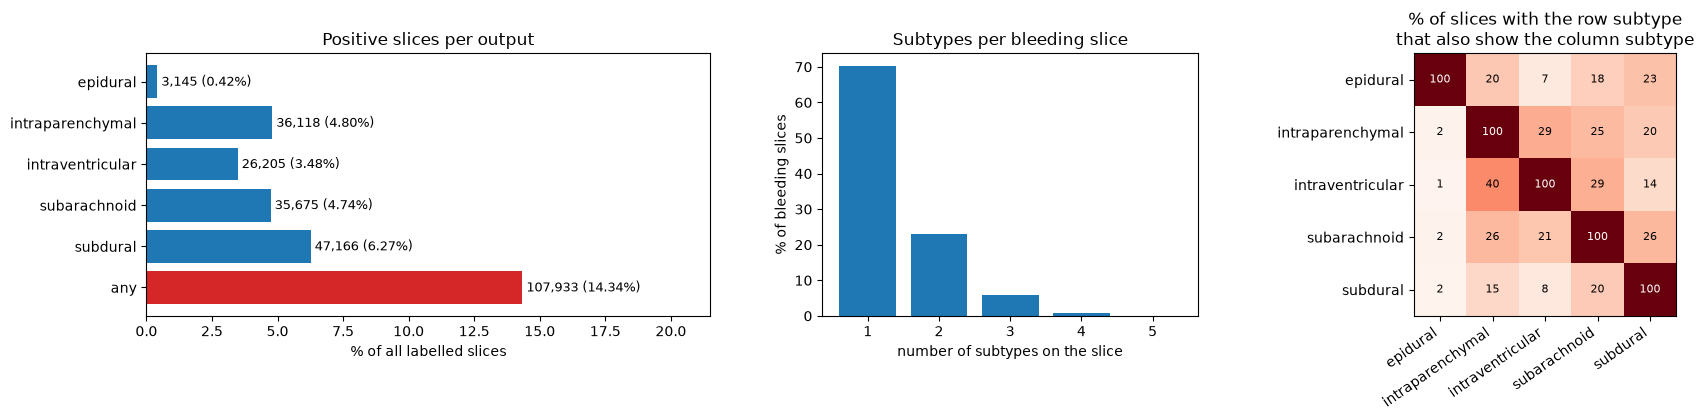

In [4]:
sub = CLASSES[:-1]
pos = labels.loc[labels["any"] == 1, sub].astype(np.int64)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3), gridspec_kw=dict(width_ratios=[1.2, 0.8, 1]))
rate = labels.mean() * 100
ax[0].barh(CLASSES[::-1], rate[CLASSES[::-1]], color=["#d62728"] + ["#1f77b4"] * 5)
for i, c in enumerate(CLASSES[::-1]):
    ax[0].text(rate[c], i, f" {int(labels[c].sum()):,} ({rate[c]:.2f}%)", va="center", fontsize=9)
ax[0].set_xlim(0, rate.max() * 1.5); ax[0].set_xlabel("% of all labelled slices"); ax[0].set_title("Positive slices per output")
k = pos.sum(1).value_counts().sort_index()
ax[1].bar(k.index.astype(str), k.values / len(pos) * 100, color="#1f77b4")
ax[1].set_xlabel("number of subtypes on the slice"); ax[1].set_ylabel("% of bleeding slices"); ax[1].set_title("Subtypes per bleeding slice")
co = (pos.T @ pos).values.astype(float)
cond = co / np.diag(co)[:, None] * 100          # row r, column c: % of slices with subtype r that also show subtype c
ax[2].imshow(cond, cmap="Reds", vmin=0, vmax=100)
ax[2].set_xticks(range(5)); ax[2].set_xticklabels(sub, rotation=35, ha="right"); ax[2].set_yticks(range(5)); ax[2].set_yticklabels(sub)
for r in range(5):
    for c in range(5):
        ax[2].text(c, r, f"{cond[r, c]:.0f}", ha="center", va="center", fontsize=8, color="white" if cond[r, c] > 60 else "black")
ax[2].set_title("% of slices with the row subtype\nthat also show the column subtype")
plt.tight_layout(); save_fig("label_distribution.png"); plt.show()

## 3. DICOM helpers

Images are cached as **Hounsfield units (int16)**, clipped to [-160, 240] HU, which covers all three windows.
The windows are applied later on the GPU, so the cache is exact and half the size of a 3-window uint8 cache.


In [5]:
WINDOWS = [(40, 80), (80, 200), (40, 380)]       # brain, blood/subdural, soft tissue (level, width)
WIN_NAMES = ["brain", "blood", "soft tissue"]
HU_MIN, HU_MAX = -160, 240
S = CFG["IMG_SIZE"]

_ZF = {"pid": None, "zf": None}
def _zip():
    # one ZipFile per process (forked workers must not share the parent's file position); threads share it safely
    if _ZF["pid"] != os.getpid():
        _ZF["zf"], _ZF["pid"] = zipfile.ZipFile(ZIP_PATH), os.getpid()
    return _ZF["zf"]

def read_bytes(split, image_id, n=-1):
    # first n bytes (all if n=-1) of a DICOM, from the folder or from the zip
    if USE_ZIP:
        with _zip().open(ZIP_NAMES[f"{split}/{image_id}.dcm"]) as f:
            return f.read(n)
    with open(os.path.join(DATA, split, f"{image_id}.dcm"), "rb") as f:
        return f.read(n)

def to_hu(d):
    px = d.pixel_array.astype(np.float32)
    slope, intercept = float(d.RescaleSlope), float(d.RescaleIntercept)
    if int(d.BitsStored) == 12 and int(d.PixelRepresentation) == 0 and intercept > -100:   # bad 12-bit intercept fix
        px = px + 1000
        px[px >= 4096] -= 4096
        intercept = -1000.0
    return px * slope + intercept

def read_hu(item, size=S):
    # (split, image_id) -> clipped HU, resized to size x size, int16. None if unreadable.
    try:
        hu = np.clip(to_hu(pydicom.dcmread(io.BytesIO(read_bytes(*item)))), HU_MIN, HU_MAX)
        if hu.shape != (size, size):
            hu = cv2.resize(hu, (size, size), interpolation=cv2.INTER_AREA)
        return np.rint(hu).astype(np.int16)
    except Exception:
        return None

# display helpers (numpy, for figures only; the model windows on the GPU in to_input)
def window_np(hu, level, width):
    return np.clip((np.asarray(hu, np.float32) - (level - width / 2)) / width, 0, 1)

def rgb_np(hu):
    # the 3 windows as R, G, B
    return np.stack([window_np(hu, l, w) for l, w in WINDOWS], -1)

def label_str(y, sep=", "):
    names = [c for c, v in zip(CLASSES[:-1], y[:-1]) if v >= 0.5]
    return sep.join(names) if names else "no bleed"

HDR_TAGS = ["PatientID", "StudyInstanceUID", "SeriesInstanceUID", "ImagePositionPatient"]

def read_header(image_id, split):
    # Reads only the first 16 KB of the file (the header); falls back to the whole file if that isn't enough.
    try:
        d = None
        try:
            d = pydicom.dcmread(io.BytesIO(read_bytes(split, image_id, 16384)),
                                stop_before_pixels=True, specific_tags=HDR_TAGS, force=True)
            if not all(t in d for t in HDR_TAGS):
                d = None
        except Exception:
            d = None
        if d is None:
            d = pydicom.dcmread(io.BytesIO(read_bytes(split, image_id)), stop_before_pixels=True, specific_tags=HDR_TAGS)
        return (image_id, str(d.PatientID), str(d.StudyInstanceUID), str(d.SeriesInstanceUID), float(d.ImagePositionPatient[2]))
    except Exception:
        return (image_id, None, None, None, np.nan)

def proc_map(fn, items, workers, desc):
    # processes on Linux/Kaggle (fork); threads on Windows, where notebook functions can't be sent to child processes
    if os.name == "nt" or workers <= 1:
        # bounded window: ex.map would submit every item up front and buffer finished results in RAM
        from collections import deque
        workers = max(workers, 1)
        with ThreadPoolExecutor(workers) as ex, tqdm(total=len(items), desc=desc) as bar:
            pending = deque()
            for it in items:
                pending.append(ex.submit(fn, it))
                if len(pending) >= 4 * workers:
                    yield pending.popleft().result(); bar.update()
            while pending:
                yield pending.popleft().result(); bar.update()
    else:
        with Pool(workers) as pool:
            yield from tqdm(pool.imap(fn, items, chunksize=16), total=len(items), desc=desc)

def find_saved(name):
    # a header CSV saved by an earlier run, attached as an input dataset
    if not os.path.isdir("/kaggle/input"):
        return None
    for root, dirs, files in os.walk("/kaggle/input"):
        if name in files:
            return os.path.join(root, name)
        dirs[:] = [d for d in dirs if not d.startswith("stage_2")]

SCAN_CHUNK = 5_000

def scan_headers(ids, split, out_csv, saved_csv=None):
    name = os.path.basename(out_csv)
    for p in (saved_csv, out_csv, find_saved(name)):
        if p and os.path.exists(p):
            h = pd.read_csv(p)
            if set(ids) <= set(h["image"]):
                print("loaded headers from", p); return h
    # resumable: finished chunks are appended to <out_csv>.partial. A .partial from an earlier (killed) session that was
    # added as an input dataset is picked up too.
    part = out_csv + ".partial"
    old = find_saved(name + ".partial")
    if not os.path.exists(part) and old:
        shutil.copy(old, part); print("resuming from", old)
    done = set(pd.read_csv(part, usecols=["image"])["image"]) if os.path.exists(part) else set()
    todo = [i for i in ids if i not in done]
    print(f"header scan: {len(done)} already done, {len(todo)} to read with {CFG['IO_WORKERS']} threads", flush=True)
    cols = ["image", "PatientID", "StudyInstanceUID", "SeriesInstanceUID", "z"]
    fn, t0 = partial(read_header, split=split), time.time()
    with ThreadPoolExecutor(CFG["IO_WORKERS"]) as ex, tqdm(total=len(todo), desc="header scan", mininterval=2) as bar:
        for i in range(0, len(todo), SCAN_CHUNK):
            rows = []
            for r in ex.map(fn, todo[i:i + SCAN_CHUNK]):
                rows.append(r); bar.update(1)
            pd.DataFrame(rows, columns=cols).to_csv(part, mode="a", header=not os.path.exists(part), index=False)
            n = i + len(rows); rate = n / (time.time() - t0)
            # plain text line, because the tqdm widget doesn't update in a Kaggle "Save & Run All" log
            print(f"  headers {n}/{len(todo)} | {rate:.0f}/s | ETA {(len(todo) - n) / rate / 60:.0f} min", flush=True)
    h = pd.read_csv(part).drop_duplicates("image")
    h.to_csv(out_csv, index=False); os.remove(part)
    print(f"scanned {len(todo)} headers in {time.time() - t0:.0f}s, unreadable: {h['PatientID'].isna().sum()} -> {out_csv}")
    return h


## 4. Scan headers and sample whole series

The scan reads ~750k small file headers (about 5 h on Kaggle, minutes from a local zip) and saves `train_headers.csv` to the output folder.
To skip it next time on Kaggle, add this notebook's output as an input dataset: the saved file is found automatically
(or point `TRAIN_HEADERS_CSV` / `TEST_HEADERS_CSV` at it).


In [6]:
train_hdr = scan_headers(labels.index.tolist(), TRAIN_SPLIT, os.path.join(WORK, "train_headers.csv"), CFG["TRAIN_HEADERS_CSV"])
meta_all = labels.join(train_hdr.set_index("image"), how="inner").dropna(subset=["SeriesInstanceUID"]).reset_index()

ser_sizes = meta_all.groupby("SeriesInstanceUID").size()
print(f"series: {len(ser_sizes)} | patients: {meta_all.PatientID.nunique()} | slices per series: median {ser_sizes.median():.0f}, max {ser_sizes.max()}")

bytes_per_slice = S * S * 2
max_by_disk = int(0.85 * shutil.disk_usage(TMP).free / bytes_per_slice)
n_target = min(CFG["N_SLICES"], max_by_disk)
if n_target < CFG["N_SLICES"]:
    print(f"!! only room for {n_target} slices in {TMP}; reduce IMG_SIZE to fit more")

shuffled = ser_sizes.sample(frac=1, random_state=CFG["SEED"])
chosen = shuffled.index[(shuffled.cumsum() <= n_target).values]
meta = (meta_all[meta_all.SeriesInstanceUID.isin(chosen)]
          .sort_values(["SeriesInstanceUID", "z", "image"]).reset_index(drop=True))
meta["row"] = np.arange(len(meta))
g = meta.groupby("SeriesInstanceUID")
meta["pos"], meta["n"] = g.cumcount(), g["row"].transform("size")
meta["prev_row"] = meta["row"] - (meta["pos"] > 0)
meta["next_row"] = meta["row"] + (meta["pos"] < meta["n"] - 1)
print(f"sampled {len(chosen)} series, {len(meta)} slices, {meta.PatientID.nunique()} patients ({len(meta) * bytes_per_slice / 1e9:.1f} GB cache)")
display(pd.DataFrame({"positives": meta[CLASSES].sum(), "rate_%": (meta[CLASSES].mean() * 100).round(3)}))
print(elapsed())

loaded headers from d:\ML\Brain Bleed Detection on CT\Notebook\work\train_headers.csv
series: 21744 | patients: 18938 | slices per series: median 33, max 60
sampled 4337 series, 149976 slices, 4183 patients (19.7 GB cache)


,positives,rate_%
epidural,542,0.361
intraparenchymal,6885,4.591
intraventricular,4938,3.293
subarachnoid,7328,4.886
subdural,9536,6.358
any,21489,14.328


[0 min since start]


### What a series looks like

A **series** is one stack of axial slices through the head. Sorting by `ImagePositionPatient[2]` (z) puts them in anatomical order,
which is what makes the 2.5D input and the sequence model possible. Bleeds usually span several neighbouring slices, so a slice's
neighbours carry real information about it.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\series_stats.png


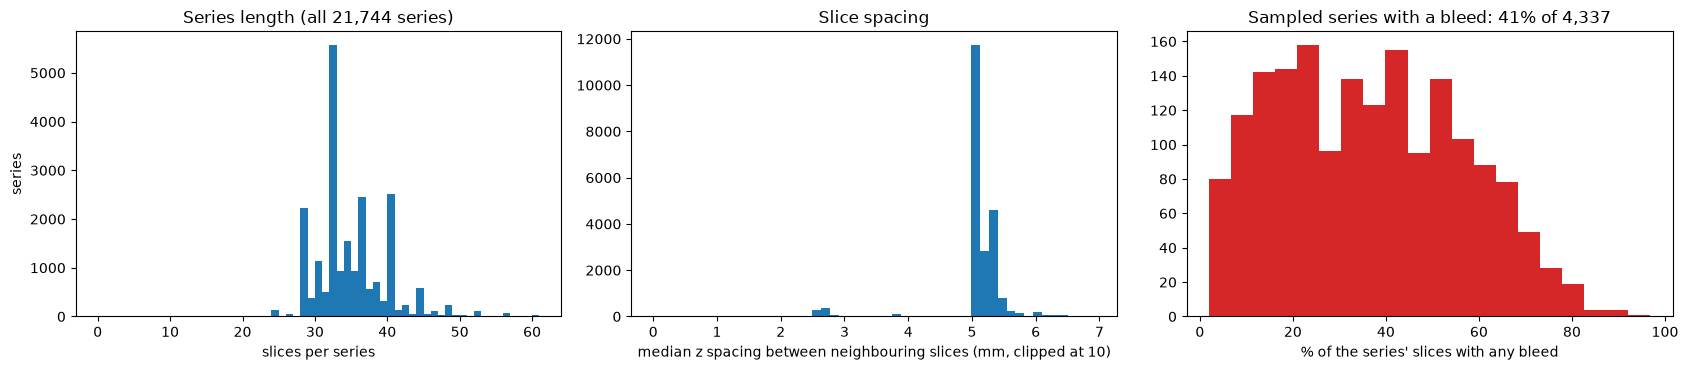

In [7]:
srt = meta_all.sort_values(["SeriesInstanceUID", "z"])
dz = srt.groupby("SeriesInstanceUID")["z"].diff().groupby(srt["SeriesInstanceUID"]).median()
any_frac = meta.groupby("SeriesInstanceUID")["any"].mean()
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
ax[0].hist(ser_sizes, bins=range(0, int(ser_sizes.max()) + 2), color="#1f77b4")
ax[0].set_xlabel("slices per series"); ax[0].set_ylabel("series"); ax[0].set_title(f"Series length (all {len(ser_sizes):,} series)")
ax[1].hist(dz.dropna().clip(0, 10), bins=50, color="#1f77b4")
ax[1].set_xlabel("median z spacing between neighbouring slices (mm, clipped at 10)"); ax[1].set_title("Slice spacing")
ax[2].hist(any_frac[any_frac > 0] * 100, bins=20, color="#d62728")
ax[2].set_xlabel("% of the series' slices with any bleed")
ax[2].set_title(f"Sampled series with a bleed: {(any_frac > 0).mean() * 100:.0f}% of {len(any_frac):,}")
plt.tight_layout(); save_fig("series_stats.png"); plt.show()

## 5. Cache the sampled slices (int16 HU memmap in /tmp)


In [8]:
CACHE = os.path.join(TMP, f"train_hu_{len(meta)}_{S}.npy")
paths = [(TRAIN_SPLIT, i) for i in meta["image"]]
bad, t0 = [], time.time()
# stream slices straight to a .npy file (same format np.load reads); a w+ memmap keeps every
# written page resident on Windows and fills RAM on a 16 GB machine
blank = np.full((S, S), HU_MIN, np.int16).tobytes()
with open(CACHE, "wb") as f:
    np.lib.format.write_array_header_1_0(f, {"descr": np.lib.format.dtype_to_descr(np.dtype(np.int16)),
                                             "fortran_order": False, "shape": (len(meta), S, S)})
    for i, hu in enumerate(proc_map(read_hu, paths, CFG["PREP_WORKERS"], "caching")):
        if hu is None:
            bad.append(i); f.write(blank)
        else:
            f.write(np.ascontiguousarray(hu, dtype=np.int16).tobytes())
print(f"cached {len(meta)} slices in {(time.time() - t0) / 60:.1f} min, unreadable: {len(bad)}", elapsed())
meta.drop(columns=["StudyInstanceUID"]).to_csv(os.path.join(WORK, "subset_meta.csv"), index=False)

caching:   0%|          | 0/149976 [00:00<?, ?it/s]

cached 149976 slices in 3.8 min, unreadable: 0 [4 min since start]


## 6. Look at the data

**CT windows.** CT pixels are Hounsfield units (HU): air ≈ −1000, water/CSF ≈ 0, brain 20–45, fresh blood 50–90, bone > 300.
A screen shows ~256 grey levels, so each _window_ (level/width) stretches one HU range to full contrast:

| Window      | Level / width | HU range   | Shows                                    |
| ----------- | ------------- | ---------- | ---------------------------------------- |
| brain       | 40 / 80       | 0 … 80     | grey/white matter, most bleeds           |
| blood       | 80 / 200      | −20 … 180  | blood against bone, subdural collections |
| soft tissue | 40 / 380      | −150 … 230 | scalp, extra-axial spaces                |

The three windows go into the model as separate channels; shown together as R, G, B they make the "RGB stack" in the last column.
One example slice per subtype (where possible a slice with only that subtype), plus a slice without bleeding:


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\output.png


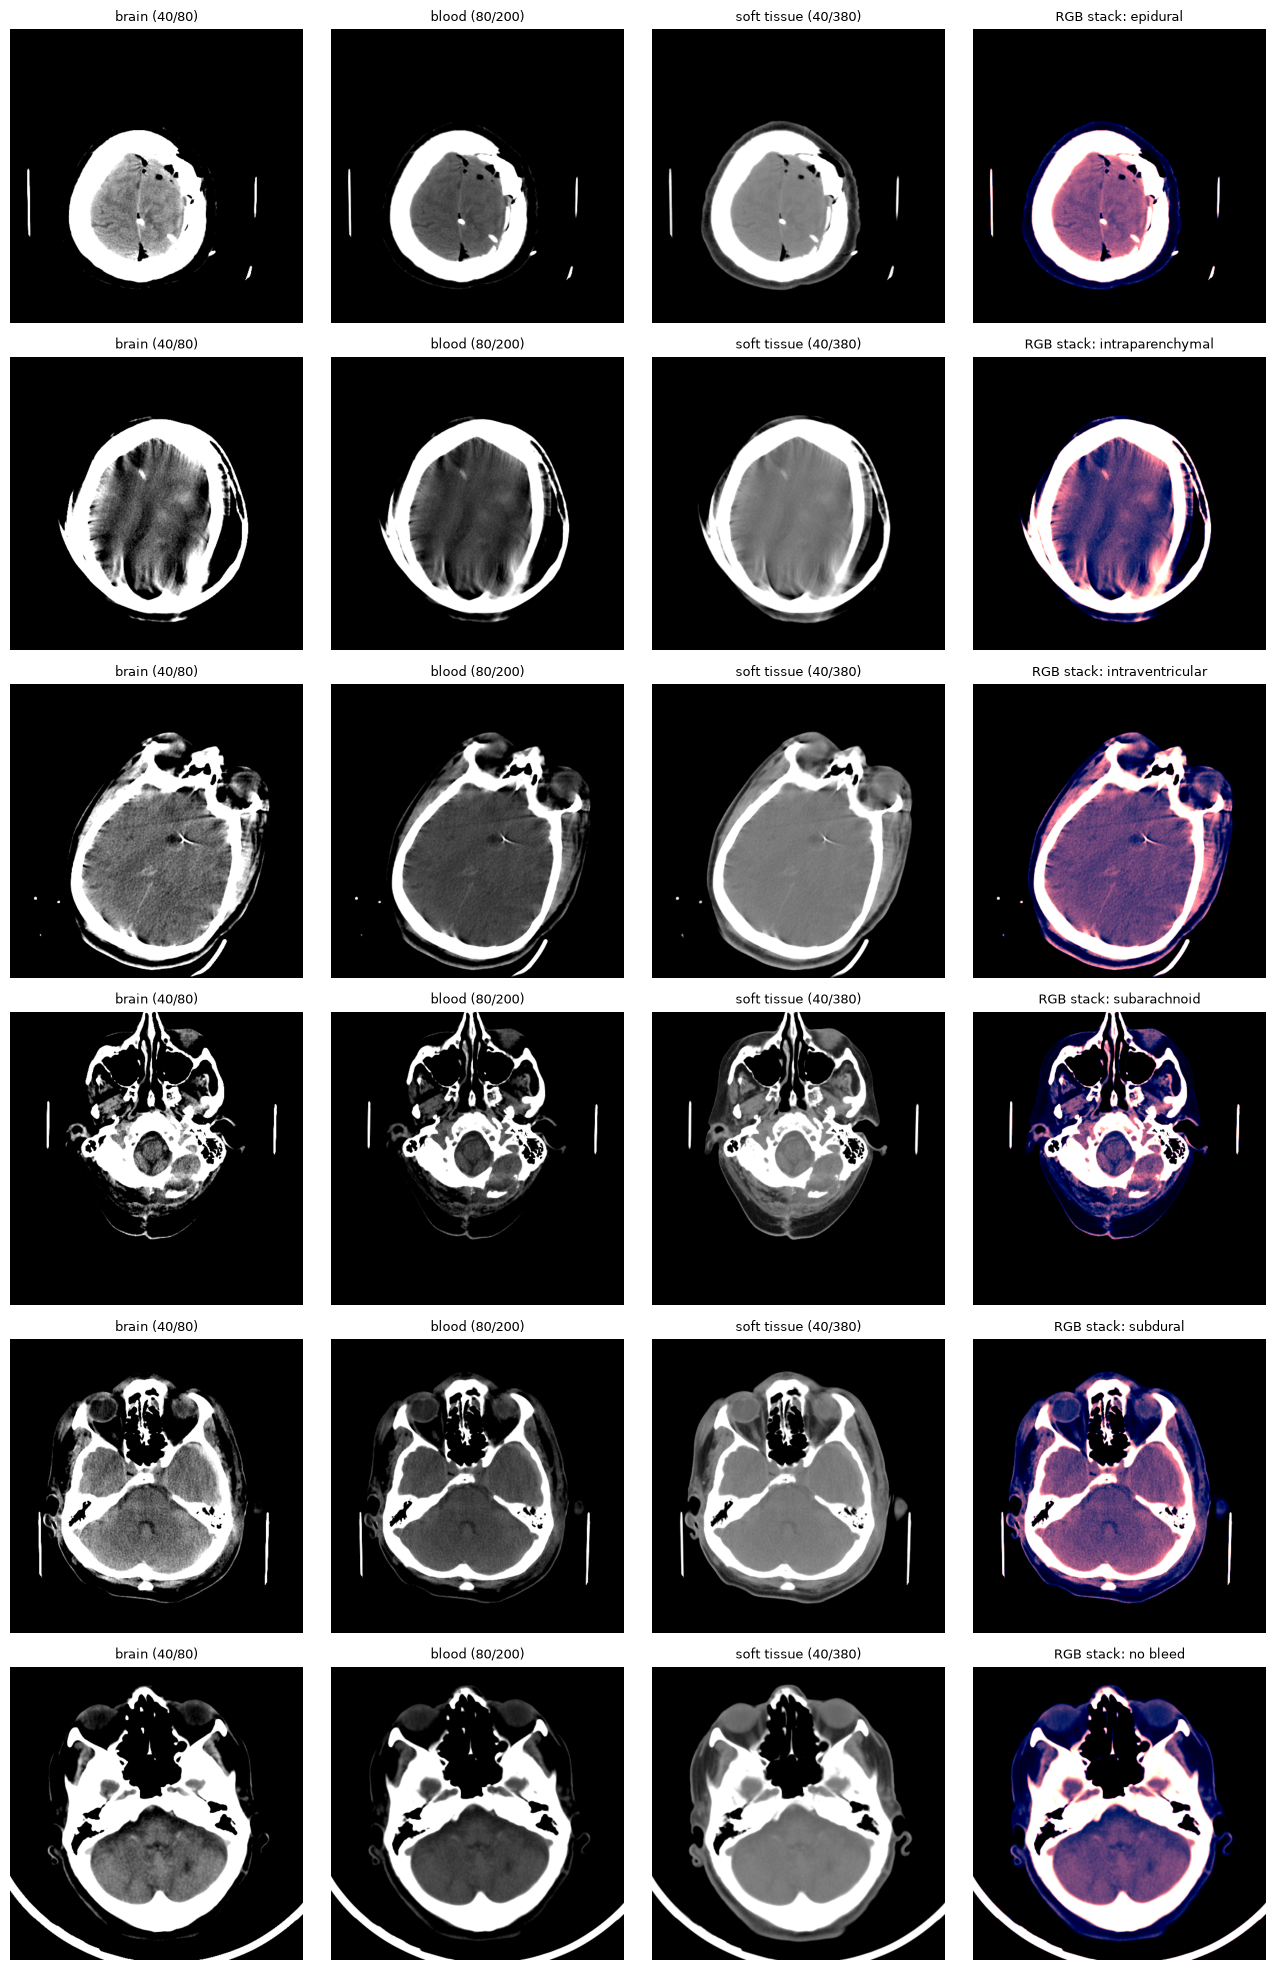

In [9]:
CACHE_ARR = np.load(CACHE, mmap_mode="r")
usable = ~meta["row"].isin(bad)

def pick_examples(frame, seed=0):
    # one slice per subtype (preferring slices that show only that subtype) and one slice without bleeding
    rng, out = np.random.RandomState(seed), []
    ok = ~frame["row"].isin(bad)
    for c in CLASSES[:-1]:
        cand = frame[ok & (frame[c] == 1) & (frame[CLASSES[:-1]].sum(1) == 1)]
        cand = cand if len(cand) else frame[ok & (frame[c] == 1)]
        if len(cand): out.append(cand.iloc[rng.randint(len(cand))])
    neg = frame[ok & (frame["any"] == 0)]
    if len(neg): out.append(neg.iloc[rng.randint(len(neg))])
    return pd.DataFrame(out)

def full_res(split, image_id, fallback=None):
    # 512 px straight from the DICOM for sharper figures; the cached 256 px slice if that fails
    hu = read_hu((split, image_id), size=512)
    return hu if hu is not None else fallback

ex = pick_examples(meta)
fig, axes = plt.subplots(len(ex), 4, figsize=(13, 3.3 * len(ex)), squeeze=False)
for r, (_, s) in enumerate(ex.iterrows()):
    hu = full_res(TRAIN_SPLIT, s["image"], CACHE_ARR[int(s["row"])])
    for c, ((l, w), name) in enumerate(zip(WINDOWS, WIN_NAMES)):
        axes[r, c].imshow(window_np(hu, l, w), cmap="gray"); axes[r, c].set_title(f"{name} ({l}/{w})", fontsize=9)
    axes[r, 3].imshow(rgb_np(hu)); axes[r, 3].set_title(f"RGB stack: {label_str(s[CLASSES].values.astype(float))}", fontsize=9)
for a in axes.flat: a.axis("off")
plt.tight_layout(); save_fig("output.png"); plt.show()

figure saved -> d:\ML\Brain Bleed Detection on CT\assets\hu_windows.png


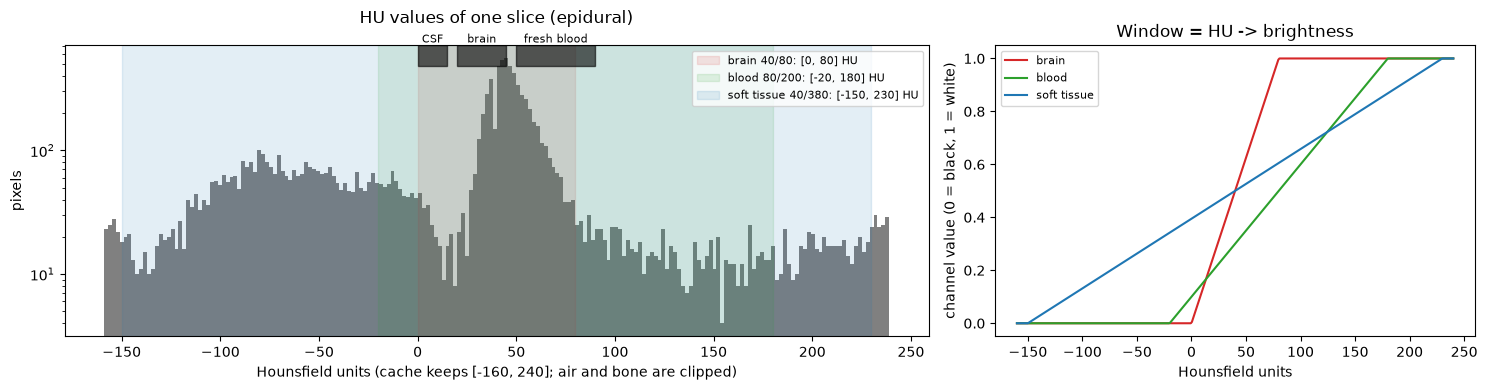

In [10]:
# HU histogram of one slice with the three windows, and how each window maps HU to brightness
s = ex.iloc[0]; hu = CACHE_ARR[int(s["row"])].astype(np.float32)
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw=dict(width_ratios=[1.8, 1]))
ax[0].hist(hu[(hu > HU_MIN) & (hu < HU_MAX)].ravel(), bins=200, color="gray")
for (l, w), name, col in zip(WINDOWS, WIN_NAMES, ["tab:red", "tab:green", "tab:blue"]):
    ax[0].axvspan(l - w / 2, l + w / 2, alpha=0.12, color=col, label=f"{name} {l}/{w}: [{l - w // 2}, {l + w // 2}] HU")
for x0, x1, txt in [(0, 15, "CSF"), (20, 45, "brain"), (50, 90, "fresh blood")]:
    ax[0].axvspan(x0, x1, ymin=0.93, ymax=1, color="k", alpha=0.6)
    ax[0].text((x0 + x1) / 2, 1.0, txt, transform=ax[0].get_xaxis_transform(), ha="center", va="bottom", fontsize=8)
ax[0].set_yscale("log"); ax[0].set_xlabel("Hounsfield units (cache keeps [-160, 240]; air and bone are clipped)")
ax[0].set_ylabel("pixels"); ax[0].legend(fontsize=8, loc="upper right"); ax[0].set_title(f"HU values of one slice ({label_str(s[CLASSES].values.astype(float))})", pad=16)
xs = np.linspace(HU_MIN, HU_MAX, 400)
for (l, w), name, col in zip(WINDOWS, WIN_NAMES, ["tab:red", "tab:green", "tab:blue"]):
    ax[1].plot(xs, window_np(xs, l, w), color=col, label=name)
ax[1].set_xlabel("Hounsfield units"); ax[1].set_ylabel("channel value (0 = black, 1 = white)"); ax[1].set_title("Window = HU -> brightness")
ax[1].legend(fontsize=8)
plt.tight_layout(); save_fig("hu_windows.png"); plt.show()

Labels along one whole series (the sampled series with the most different subtypes). Each column of the strip is one slice in z order;
the thumbnails below are evenly spaced slices from the same series.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\series_labels.png


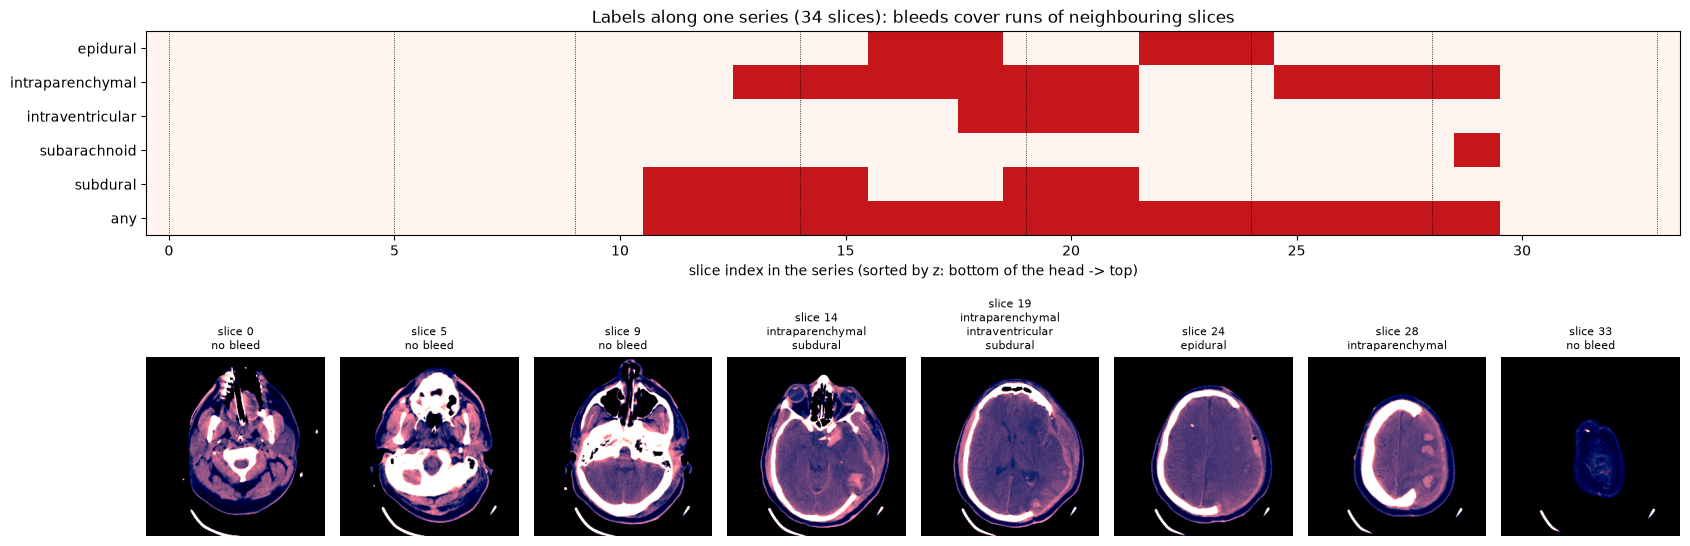

In [11]:
n_sub = meta[usable].groupby("SeriesInstanceUID")[CLASSES[:-1]].max().sum(1)
sid = n_sub.sort_values(ascending=False, kind="stable").index[0]
g = meta[meta.SeriesInstanceUID == sid]
fig = plt.figure(figsize=(17, 6.2)); gs = fig.add_gridspec(2, 8, height_ratios=[1, 1.5])
ax = fig.add_subplot(gs[0, :])
ax.imshow(g[CLASSES].values.T, aspect="auto", cmap="Reds", vmin=0, vmax=1.3, interpolation="nearest")
ax.set_yticks(range(6)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("slice index in the series (sorted by z: bottom of the head -> top)")
ax.set_title(f"Labels along one series ({len(g)} slices): bleeds cover runs of neighbouring slices")
for j, k in enumerate(np.linspace(0, len(g) - 1, 8).round().astype(int)):
    s = g.iloc[k]; ax.axvline(k, color="k", lw=0.6, ls=":")
    a = fig.add_subplot(gs[1, j]); a.imshow(rgb_np(CACHE_ARR[int(s["row"])])); a.axis("off")
    a.set_title(f"slice {k}\n{label_str(s[CLASSES].values.astype(float), sep=chr(10))}", fontsize=8)
plt.tight_layout(); save_fig("series_labels.png"); plt.show()

## 7. Patient-level split


In [12]:
gss = GroupShuffleSplit(n_splits=1, test_size=CFG["VAL_FRAC"], random_state=CFG["SEED"])
tr_idx, va_idx = next(gss.split(meta, groups=meta["PatientID"]))
tr = meta.iloc[np.sort(tr_idx)].reset_index(drop=True)
va = meta.iloc[np.sort(va_idx)].reset_index(drop=True)          # stays sorted by series and z
assert set(tr.PatientID).isdisjoint(va.PatientID), "patient leak!"
tr_fit = tr[~tr["row"].isin(bad)].reset_index(drop=True)          # never train on unreadable slices
print(f"train: {len(tr)} slices / {tr.SeriesInstanceUID.nunique()} series / {tr.PatientID.nunique()} patients")
print(f"val:   {len(va)} slices / {va.SeriesInstanceUID.nunique()} series / {va.PatientID.nunique()} patients")
display(pd.DataFrame({"train_pos": tr[CLASSES].sum(), "val_pos": va[CLASSES].sum()}))

train: 119975 slices / 3472 series / 3346 patients
val:   30001 slices / 865 series / 837 patients


,train_pos,val_pos
epidural,419,123
intraparenchymal,5382,1503
intraventricular,3879,1059
subarachnoid,5836,1492
subdural,7493,2043
any,16923,4566


## 8. Data, windowing on the GPU, model

Each sample is a stack of K int16 HU slices. On the GPU each slice is expanded into the 3 windows, giving `3*K` channels
ordered (prev: brain, blood, soft) (cur: ...) (next: ...). timm adapts the pretrained first convolution to `3*K` input channels.

**Two GPUs.** On Kaggle's T4 x2, `nn.DataParallel` with the default settings crashed inside cuDNN's batch norm on the second replica
(`CUDNN_STATUS_EXECUTION_FAILED_CUDART`). The notebook now tries several settings, each in a separate Python process so a CUDA crash
cannot kill the kernel: channels-last vs. plain NCHW memory layout, and cuDNN batch norm vs. PyTorch's own batch-norm kernel
(convolutions keep using cuDNN). The first setting that trains cleanly is used; if none does, training runs on one GPU.
Failed attempts are logged to `dp_test_errors.log` in the output folder.


In [13]:
# SliceDS is written to a small module and imported from there: Windows DataLoader workers are spawned (not forked)
# and can only load classes that live in an importable file, not ones defined in the notebook
SLICE_DS_SRC = r'''
import numpy as np, torch
from torch.utils.data import Dataset

class SliceDS(Dataset):
    def __init__(self, frame, cache_path, train, classes, k):
        self.rows = frame["row"].values
        self.prev, self.next = frame["prev_row"].values, frame["next_row"].values
        self.y = frame[classes].values.astype(np.float32)
        self.cache_path, self.train, self.k, self.arr = cache_path, train, k, None   # train: augmented on the GPU in to_input
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        if self.arr is None:                     # opened lazily, so each worker gets its own memmap
            self.arr = np.load(self.cache_path, mmap_mode="r")
        idx = [self.prev[i], self.rows[i], self.next[i]] if self.k == 3 else [self.rows[i]]
        x = torch.from_numpy(np.stack([self.arr[j] for j in idx]))   # K x S x S, int16 HU
        return x, torch.from_numpy(self.y[i])
'''
import sys, importlib
with open(os.path.join(TMP, "rsna_slice_ds.py"), "w") as f:
    f.write(SLICE_DS_SRC)
if TMP not in sys.path:
    sys.path.insert(0, TMP)
import rsna_slice_ds; importlib.reload(rsna_slice_ds)
SliceDS = partial(rsna_slice_ds.SliceDS, classes=CLASSES, k=K)

# channels_last is ~5x slower for EfficientNet on the local RTX 4060 (Windows, cuDNN 9) -> standard NCHW there;
# on Kaggle the DataParallel test below may still switch it
MEM_FMT = torch.contiguous_format if os.name == "nt" else torch.channels_last

_lo = torch.tensor([l - w / 2 for l, w in WINDOWS], device=DEVICE).view(1, 1, 3, 1, 1)
_w  = torch.tensor([float(w) for _, w in WINDOWS], device=DEVICE).view(1, 1, 3, 1, 1)
_mean = torch.tensor([0.485, 0.456, 0.406] * K, device=DEVICE).view(1, 3 * K, 1, 1)
_std  = torch.tensor([0.229, 0.224, 0.225] * K, device=DEVICE).view(1, 3 * K, 1, 1)

def gpu_augment(hu):
    # (B, K, S, S) float HU on the GPU -> random horizontal flip + affine (rotate +-10 deg, shift +-5%, scale 0.9-1.1),
    # one transform per sample, shared by its K slices; areas moved in from outside are HU_MIN
    B, dev = hu.shape[0], hu.device
    ang = torch.empty(B, device=dev).uniform_(-10, 10).deg2rad()
    sc = torch.empty(B, device=dev).uniform_(0.9, 1.1)
    tx, ty = torch.empty(2, B, device=dev).uniform_(-0.1, 0.1)          # 5% of the width; normalised coords span 2
    flip = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    c, s = ang.cos() / sc, ang.sin() / sc
    theta = torch.stack([torch.stack([c * flip, -s, tx], 1), torch.stack([s * flip, c, ty], 1)], 1)
    grid = nn.functional.affine_grid(theta, hu.shape, align_corners=False)
    out = nn.functional.grid_sample(hu - HU_MIN, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return out + HU_MIN

def to_input(hu, augment=False):
    # (B, K, S, S) HU -> (B, 3K, S, S) windowed + ImageNet-normalised, on the GPU
    hu = hu.to(DEVICE, non_blocking=True).float()
    if augment:
        hu = gpu_augment(hu)
    hu = hu.unsqueeze(2)
    x = ((hu - _lo) / _w).clamp_(0, 1).flatten(1, 2)
    return ((x - _mean) / _std).contiguous(memory_format=MEM_FMT)

class Net(nn.Module):
    def __init__(self, name, in_chans, pretrained):
        super().__init__()
        self.backbone = timm.create_model(name, pretrained=pretrained, num_classes=0, in_chans=in_chans)
        self.drop = nn.Dropout(0.2)
        self.head = nn.Linear(self.backbone.num_features, 6)
    def forward(self, x, return_feat=False):
        f = self.backbone(x)
        logit = self.head(self.drop(f))
        return (logit, f) if return_feat else logit

dl_kw = dict(batch_size=CFG["BATCH"], num_workers=LOADER_WORKERS, pin_memory=DEVICE == "cuda",
             persistent_workers=LOADER_WORKERS > 0)
train_dl = DataLoader(SliceDS(tr_fit, CACHE, True), shuffle=True, drop_last=True, **dl_kw)
val_dl   = DataLoader(SliceDS(va, CACHE, False), shuffle=False, **dl_kw)

def native_batch_norm(input, running_mean, running_var, weight=None, bias=None, training=False, momentum=0.1, eps=1e-5):
    # same as F.batch_norm, but always PyTorch's own CUDA kernel instead of cuDNN's batch norm
    return torch.batch_norm(input, weight, bias, running_mean, running_var, training, momentum, eps, False)

# DataParallel settings to try, fastest first
DP_VARIANTS = [dict(channels_last=True,  native_bn=False),
               dict(channels_last=True,  native_bn=True),
               dict(channels_last=False, native_bn=True),
               dict(channels_last=False, native_bn=False)]

DP_TEST = r"""
import json, sys, torch, torch.nn as nn, timm
c = json.loads(sys.argv[1])
if c["native_bn"]:
    def native_batch_norm(input, running_mean, running_var, weight=None, bias=None, training=False, momentum=0.1, eps=1e-5):
        return torch.batch_norm(input, weight, bias, running_mean, running_var, training, momentum, eps, False)
    nn.functional.batch_norm = native_batch_norm
fmt = torch.channels_last if c["channels_last"] else torch.contiguous_format
net = timm.create_model(c["backbone"], pretrained=False, num_classes=6, in_chans=c["chans"]).cuda().to(memory_format=fmt)
model = nn.DataParallel(net)
opt = torch.optim.AdamW(model.parameters(), 1e-4); scaler = torch.amp.GradScaler()
for _ in range(3):
    x = torch.randn(c["batch"], c["chans"], c["size"], c["size"], device="cuda").contiguous(memory_format=fmt)
    with torch.autocast("cuda"):
        loss = model(x).float().mean()
    opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
model.eval()
with torch.no_grad(), torch.autocast("cuda"):
    model(x); model(x[: c["batch"] // 2 + 1])      # also an uneven split, like the last validation batch
torch.cuda.synchronize(); print("DP_OK")
"""

def pick_dp_variant():
    # Runs a few DataParallel training steps (same backbone, batch, image size, AMP) per setting in a separate Python process,
    # because a CUDA error can leave the process unusable. Returns the first setting that works, or None (-> 1 GPU).
    import sys
    script, log = os.path.join(TMP, "dp_test.py"), os.path.join(WORK, "dp_test_errors.log")
    with open(script, "w") as f:
        f.write(DP_TEST)
    for v in DP_VARIANTS:
        arg = json.dumps(dict(v, backbone=CFG["BACKBONE"], chans=3 * K, batch=CFG["BATCH"], size=S))
        try:
            r = subprocess.run([sys.executable, script, arg], capture_output=True, text=True, timeout=600)
            ok, err = r.returncode == 0 and "DP_OK" in r.stdout, (r.stderr or r.stdout).strip()
        except subprocess.TimeoutExpired:
            ok, err = False, "timed out after 10 min"
        last = err.splitlines()[-1] if err else f"exit code {r.returncode}"
        print(f"  DataParallel test {v}: " + ("ok" if ok else "failed: " + last[:200]), flush=True)
        if ok:
            return v
        with open(log, "a") as f:
            f.write(f"{v}\n{err[-6000:]}\n\n")
    return None

DP_SETTING = None
if CFG["MULTI_GPU"] and torch.cuda.device_count() > 1:
    DP_SETTING = pick_dp_variant()
    if DP_SETTING is None:
        print("DataParallel: every setting failed -> training on 1 GPU (details in dp_test_errors.log)")
    else:
        MEM_FMT = torch.channels_last if DP_SETTING["channels_last"] else torch.contiguous_format
        if DP_SETTING["native_bn"]:
            nn.functional.batch_norm = native_batch_norm      # same as in the test that passed
        print("DataParallel: using", DP_SETTING)
USE_DP = DP_SETTING is not None
net = Net(CFG["BACKBONE"], 3 * K, CFG["PRETRAINED"]).to(DEVICE).to(memory_format=MEM_FMT)
model = nn.DataParallel(net) if USE_DP else net
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "|", f"DataParallel over {torch.cuda.device_count()} GPUs" if USE_DP else "single GPU")
N_FEAT = net.backbone.num_features
print(CFG["BACKBONE"], "| input channels:", 3 * K, "| feature size:", N_FEAT,
      "| params: %.1fM" % (sum(p.numel() for p in net.parameters()) / 1e6))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | single GPU
tf_efficientnet_b2.ns_jft_in1k | input channels: 9 | feature size: 1408 | params: 7.7M


## 9. What the model sees

The 9 input channels for one training slice: rows are the previous, current and next slice of the series, columns the three windows.
The neighbouring slices let the CNN tell a small bleed from noise or bone artefacts that appear on only one slice.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\context_input.png


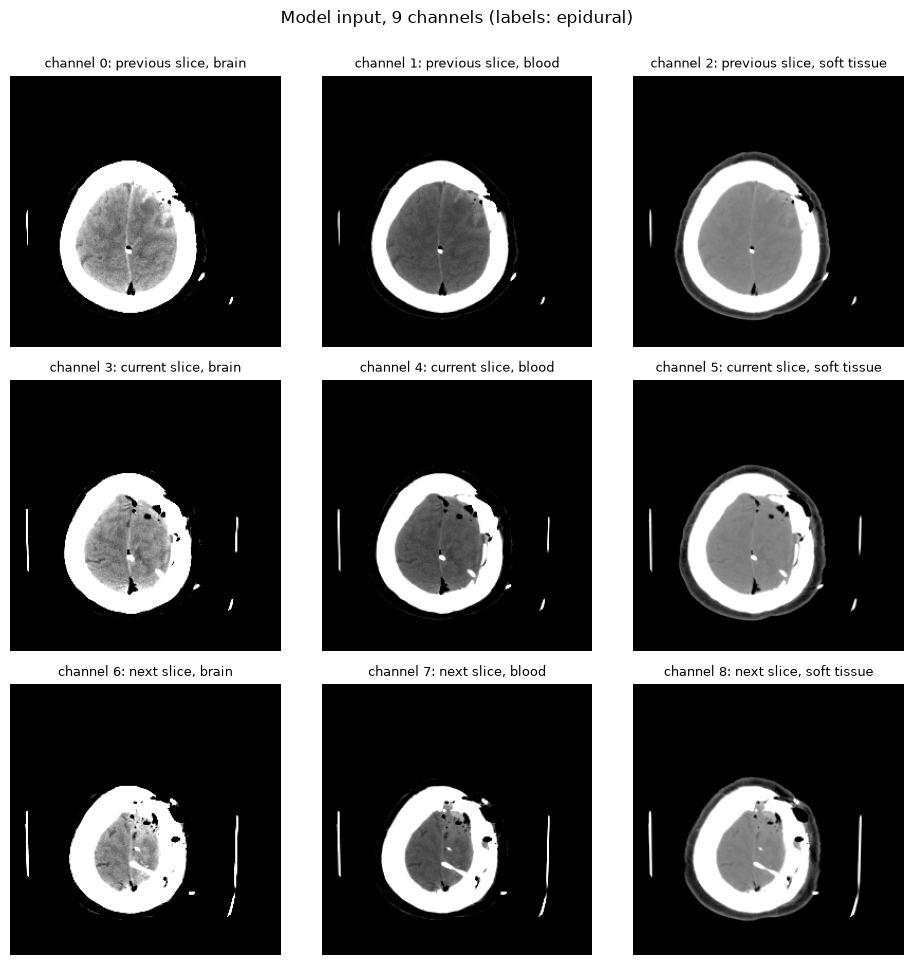

In [14]:
ds_show = SliceDS(ex, CACHE, train=False)
x0, y0 = ds_show[0]; x0 = x0.float().numpy()
names = ["previous", "current", "next"] if K == 3 else ["current"]
fig, axes = plt.subplots(K, 3, figsize=(9.5, 3.2 * K), squeeze=False)
for r in range(K):
    for c, ((l, w), wn) in enumerate(zip(WINDOWS, WIN_NAMES)):
        axes[r, c].imshow(window_np(x0[r], l, w), cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(f"channel {3 * r + c}: {names[r]} slice, {wn}", fontsize=9)
fig.suptitle(f"Model input, {3 * K} channels (labels: {label_str(y0.numpy())})", y=1.0)
plt.tight_layout(); save_fig("context_input.png"); plt.show()

**Augmentation.** During training every sample gets a random horizontal flip and a small random affine transform
(±10° rotation, ±5% shift, 0.9–1.1 scale). The same transform is applied to all K slices, so they stay aligned.
Shown in the blood window, current slice:


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\augmentation.png


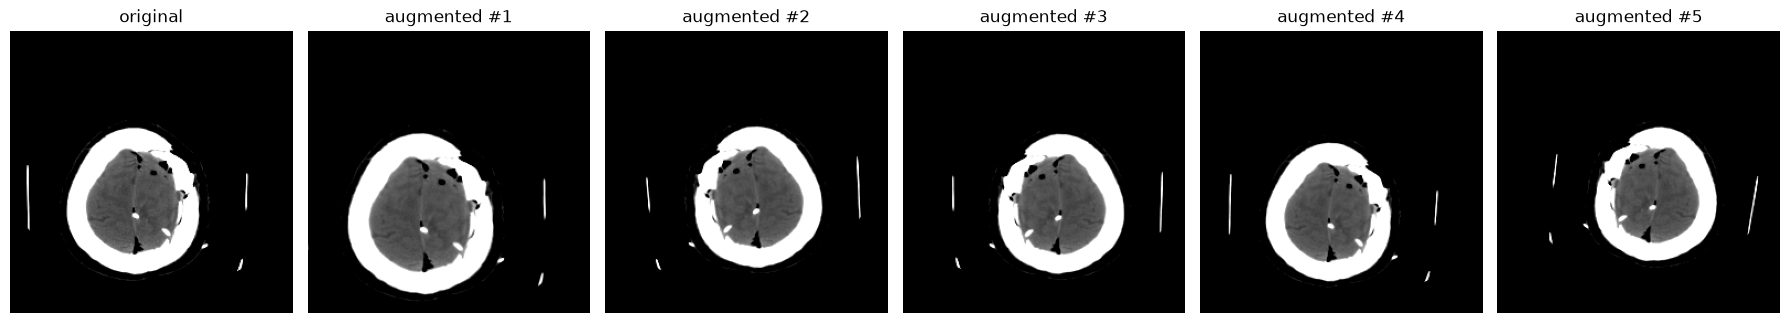

In [15]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
axes[0].imshow(window_np(x0[K // 2], *WINDOWS[1]), cmap="gray"); axes[0].set_title("original")
for j in range(1, 6):
    xa = gpu_augment(ds_show[0][0][None].to(DEVICE).float())[0].cpu().numpy()
    axes[j].imshow(window_np(xa[K // 2], *WINDOWS[1]), cmap="gray"); axes[j].set_title(f"augmented #{j}")
for a in axes: a.axis("off")
plt.tight_layout(); save_fig("augmentation.png"); plt.show()

## 10. Train the CNN (stage 1)


In [16]:
W_T = torch.tensor(CLASS_W, device=DEVICE)
loss_fn = nn.BCEWithLogitsLoss(weight=W_T)
opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["LR"], total_steps=CFG["EPOCHS"] * len(train_dl), pct_start=0.1)
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
AMP = dict(device_type=DEVICE, enabled=DEVICE == "cuda")

def weighted_logloss(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    per_class = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean(0)
    return float((per_class * CLASS_W).sum() / CLASS_W.sum())

@torch.no_grad()
def infer(hu, tta=True):
    # returns probabilities (B, 6) and pooled features (B, F), averaged over a horizontal flip when tta=True
    model.eval()
    x = to_input(hu)
    with torch.autocast(**AMP):
        l, f = model(x, True)
        p, f = torch.sigmoid(l.float()), f.float()
        if tta:
            l2, f2 = model(x.flip(-1), True)
            p, f = (p + torch.sigmoid(l2.float())) / 2, (f + f2.float()) / 2
    return p.cpu().numpy(), f.half().cpu().numpy()

def predict(dl, tta=True):
    P, F = [], []
    for hu, _ in tqdm(dl, leave=False):
        p, f = infer(hu, tta); P.append(p); F.append(f)
    return np.concatenate(P), np.concatenate(F)

def gpu_preflight():
    # one forward/backward on a real batch, synchronised, so a CUDA problem shows its actual message here
    # instead of killing the kernel in the middle of the training loop
    hu, y = next(iter(DataLoader(SliceDS(tr_fit.iloc[:CFG["BATCH"]], CACHE, True), batch_size=CFG["BATCH"])))
    model.train()
    try:
        with torch.autocast(**AMP):
            loss = loss_fn(model(to_input(hu, augment=True)), y.to(DEVICE))
        loss.backward()
        if DEVICE == "cuda": torch.cuda.synchronize()
    except torch.cuda.OutOfMemoryError as e:
        raise RuntimeError(f"GPU out of memory at BATCH={CFG['BATCH']}: lower CFG['BATCH'] or IMG_SIZE") from e
    except RuntimeError as e:
        raise RuntimeError("GPU preflight failed. If DataParallel is on, set MULTI_GPU=False; otherwise re-run with "
                           "os.environ['CUDA_LAUNCH_BLOCKING']='1' set in the first cell to locate the failing op.") from e
    opt.zero_grad(set_to_none=True)
    mem = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else 0
    print(f"GPU preflight ok: loss {loss.item():.4f} | peak GPU memory {mem:.1f} GB")
gpu_preflight()

BEST_PATH = os.path.join(WORK, "best_cnn.pt")
best, history, t_train = 1e9, [], time.time()
# hours available for training: TRAIN_HOURS, and never so long that the 12 h Kaggle session ends before the submission is written
budget_h = min(CFG["TRAIN_HOURS"], CFG["SESSION_HOURS"] - CFG["RESERVE_HOURS"] - (time.time() - T0) / 3600)
print(f"training budget: {budget_h:.1f} h")
for ep in range(CFG["EPOCHS"]):
    if history and (time.time() - t_train + history[-1]["sec"]) / 3600 > budget_h:
        print("stopping: next epoch would exceed the training time budget"); break
    model.train(); t0, run = time.time(), 0.0
    pbar = tqdm(train_dl, desc=f"epoch {ep + 1}/{CFG['EPOCHS']}")
    for step, (hu, y) in enumerate(pbar):
        x, y = to_input(hu, augment=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(**AMP):
            loss = loss_fn(model(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        if step % 50 == 0:                       # .item() waits for the GPU, so only read the loss now and then
            run = 0.7 * run + 0.3 * loss.item() if step else loss.item()
            pbar.set_postfix(loss=f"{run:.4f}")
    p_val, _ = predict(val_dl, tta=False)
    wll = weighted_logloss(va[CLASSES].values, p_val)
    auc_any = roc_auc_score(va["any"], p_val[:, -1]) if 0 < va["any"].sum() < len(va) else np.nan
    history.append(dict(epoch=ep + 1, train_loss=run, val_wlogloss=wll, val_auc_any=auc_any, sec=time.time() - t0))
    print(f"epoch {ep + 1}: train {run:.4f} | val weighted logloss {wll:.4f} | AUC(any) {auc_any:.4f} | {time.time() - t0:.0f}s", elapsed())
    if wll < best:
        best = wll; torch.save(net.state_dict(), BEST_PATH); print("  saved best ->", BEST_PATH)
pd.DataFrame(history).to_csv(os.path.join(WORK, "history.csv"), index=False)
pd.DataFrame(history)

GPU preflight ok: loss 0.8056 | peak GPU memory 4.3 GB
training budget: 4.0 h


epoch 1/5:   0%|          | 0/2499 [00:07<?, ?it/s]

  0%|          | 0/626 [00:14<?, ?it/s]

epoch 1: train 0.0962 | val weighted logloss 0.1118 | AUC(any) 0.9477 | 490s [13 min since start]
  saved best -> d:\ML\Brain Bleed Detection on CT\Notebook\work\best_cnn.pt


epoch 2/5:   0%|          | 0/2499 [00:00<?, ?it/s]

  0%|          | 0/626 [00:00<?, ?it/s]

... (7 outputs left out)

epoch 5/5:   0%|          | 0/2499 [00:00<?, ?it/s]

  0%|          | 0/626 [00:00<?, ?it/s]

epoch 5: train 0.0484 | val weighted logloss 0.1221 | AUC(any) 0.9561 | 471s [44 min since start]


,epoch,train_loss,val_wlogloss,val_auc_any,sec
0,1,0.096220,0.111825,0.947678,489.847755
1,2,0.105453,0.104575,0.961128,469.793799
2,3,0.057897,0.100774,0.962177,469.422156
3,4,0.043894,0.112844,0.956975,471.719599
4,5,0.048415,0.122094,0.956139,471.069934


## 11. Evaluate the CNN per subtype and extract validation features


In [17]:
net.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
p_val1, f_val = predict(val_dl, tta=True)
y_val = va[CLASSES].values
prior = tr[CLASSES].values.mean(0)

def report(y, p, name):
    rows = []
    for k, c in enumerate(CLASSES):
        pk = np.clip(p[:, k], 1e-7, 1 - 1e-7)
        rows.append({"subtype": c, "val_positives": int(y[:, k].sum()),
                     f"logloss_{name}": log_loss(y[:, k], pk, labels=[0, 1]),
                     f"auc_{name}": roc_auc_score(y[:, k], pk) if 0 < y[:, k].sum() < len(y) else np.nan})
    return pd.DataFrame(rows).set_index("subtype")

rep = report(y_val, p_val1, "cnn")
rep.insert(1, "baseline_logloss", [log_loss(y_val[:, k], np.full(len(y_val), prior[k]), labels=[0, 1]) for k in range(6)])
WLL_CNN = weighted_logloss(y_val, p_val1)
display(rep.round(4)); print(f"CNN weighted log loss (val, flip TTA): {WLL_CNN:.4f}", elapsed())

  0%|          | 0/626 [00:00<?, ?it/s]

,val_positives,baseline_logloss,logloss_cnn,auc_cnn
subtype,,,,
epidural,123,0.0267,0.0217,0.9366
intraparenchymal,1503,0.1991,0.0678,0.9790
intraventricular,1059,0.1528,0.0418,0.9899
subarachnoid,1492,0.1977,0.1020,0.9460
subdural,2043,0.2490,0.1279,0.9455
any,4566,0.4270,0.1589,0.9641


CNN weighted log loss (val, flip TTA): 0.0970 [45 min since start]


### ROC curves and training curve

ROC: how well each output ranks bleeding slices above normal ones at every threshold (AUC 0.5 = chance, 1.0 = perfect).
Training curve: if the validation loss turns up while the training loss keeps falling, the model is overfitting; the checkpoint with
the best validation loss is the one used.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\roc_training_curves.png


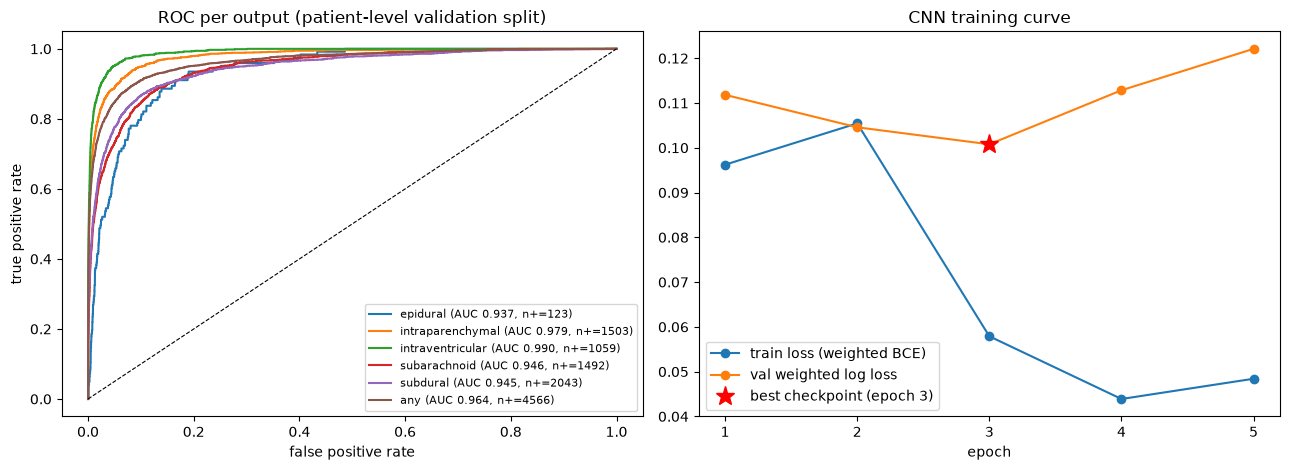

In [18]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for k, c in enumerate(CLASSES):
    if 0 < y_val[:, k].sum() < len(y_val):
        fpr, tpr, _ = roc_curve(y_val[:, k], p_val1[:, k])
        ax[0].plot(fpr, tpr, label=f"{c} (AUC {rep.loc[c, 'auc_cnn']:.3f}, n+={int(y_val[:, k].sum())})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_title("ROC per output (patient-level validation split)"); ax[0].legend(fontsize=8, loc="lower right")
h = pd.DataFrame(history)
ax[1].plot(h.epoch, h.train_loss, "o-", label="train loss (weighted BCE)")
ax[1].plot(h.epoch, h.val_wlogloss, "o-", label="val weighted log loss")
b = h.loc[h.val_wlogloss.idxmin()]
ax[1].plot(b.epoch, b.val_wlogloss, "r*", ms=14, label=f"best checkpoint (epoch {int(b.epoch)})")
ax[1].set_xlabel("epoch"); ax[1].set_xticks(h.epoch); ax[1].set_title("CNN training curve"); ax[1].legend()
plt.tight_layout(); save_fig("roc_training_curves.png"); plt.show()

### Calibration

Log loss punishes confident mistakes, so the probabilities must mean what they say. Left: for slices predicted at about _p_,
the fraction that really is positive (on the diagonal = well calibrated). Right: predicted p(any) for normal and bleeding slices;
the less the two histograms overlap, the better the separation.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\calibration.png


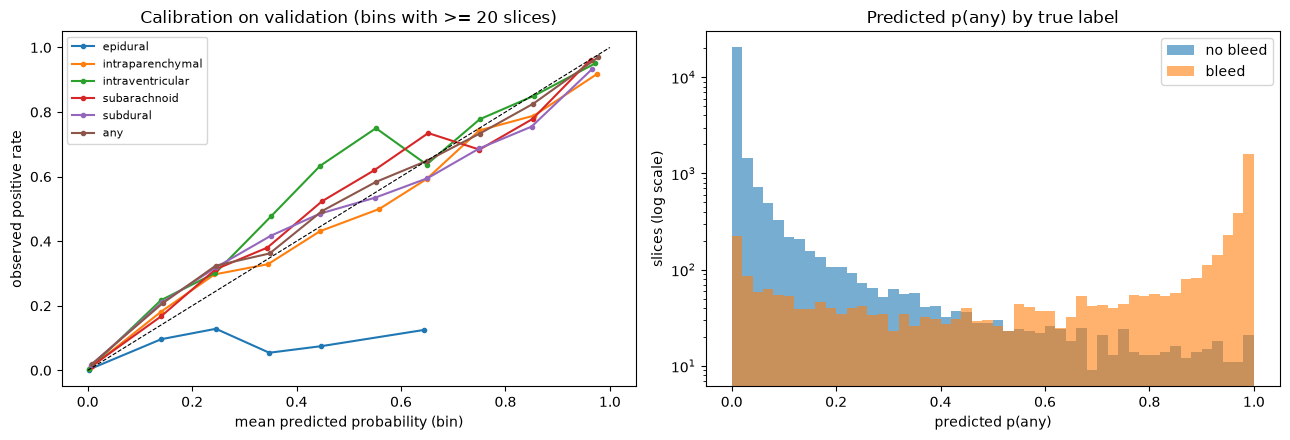

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
edges = np.linspace(0, 1, 11)
for k, c in enumerate(CLASSES):
    b = np.clip(np.digitize(p_val1[:, k], edges[1:-1]), 0, 9)
    pts = [(p_val1[b == j, k].mean(), y_val[b == j, k].mean()) for j in range(10) if (b == j).sum() >= 20]
    if pts: ax[0].plot(*zip(*pts), "o-", ms=3, label=c)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("mean predicted probability (bin)"); ax[0].set_ylabel("observed positive rate")
ax[0].set_title("Calibration on validation (bins with >= 20 slices)"); ax[0].legend(fontsize=8)
ax[1].hist(p_val1[y_val[:, -1] == 0, -1], bins=50, range=(0, 1), alpha=0.6, label="no bleed", log=True)
ax[1].hist(p_val1[y_val[:, -1] == 1, -1], bins=50, range=(0, 1), alpha=0.6, label="bleed", log=True)
ax[1].set_xlabel("predicted p(any)"); ax[1].set_ylabel("slices (log scale)"); ax[1].set_title("Predicted p(any) by true label"); ax[1].legend()
plt.tight_layout(); save_fig("calibration.png"); plt.show()

### Example predictions on validation slices

Top row: bleeding slices the model is most sure about. Middle: normal slices with the highest p(any) (false alarms).
Bottom: bleeding slices with the lowest p(any) (missed bleeds). Titles show the true labels and the outputs above 0.5.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\val_predictions.png


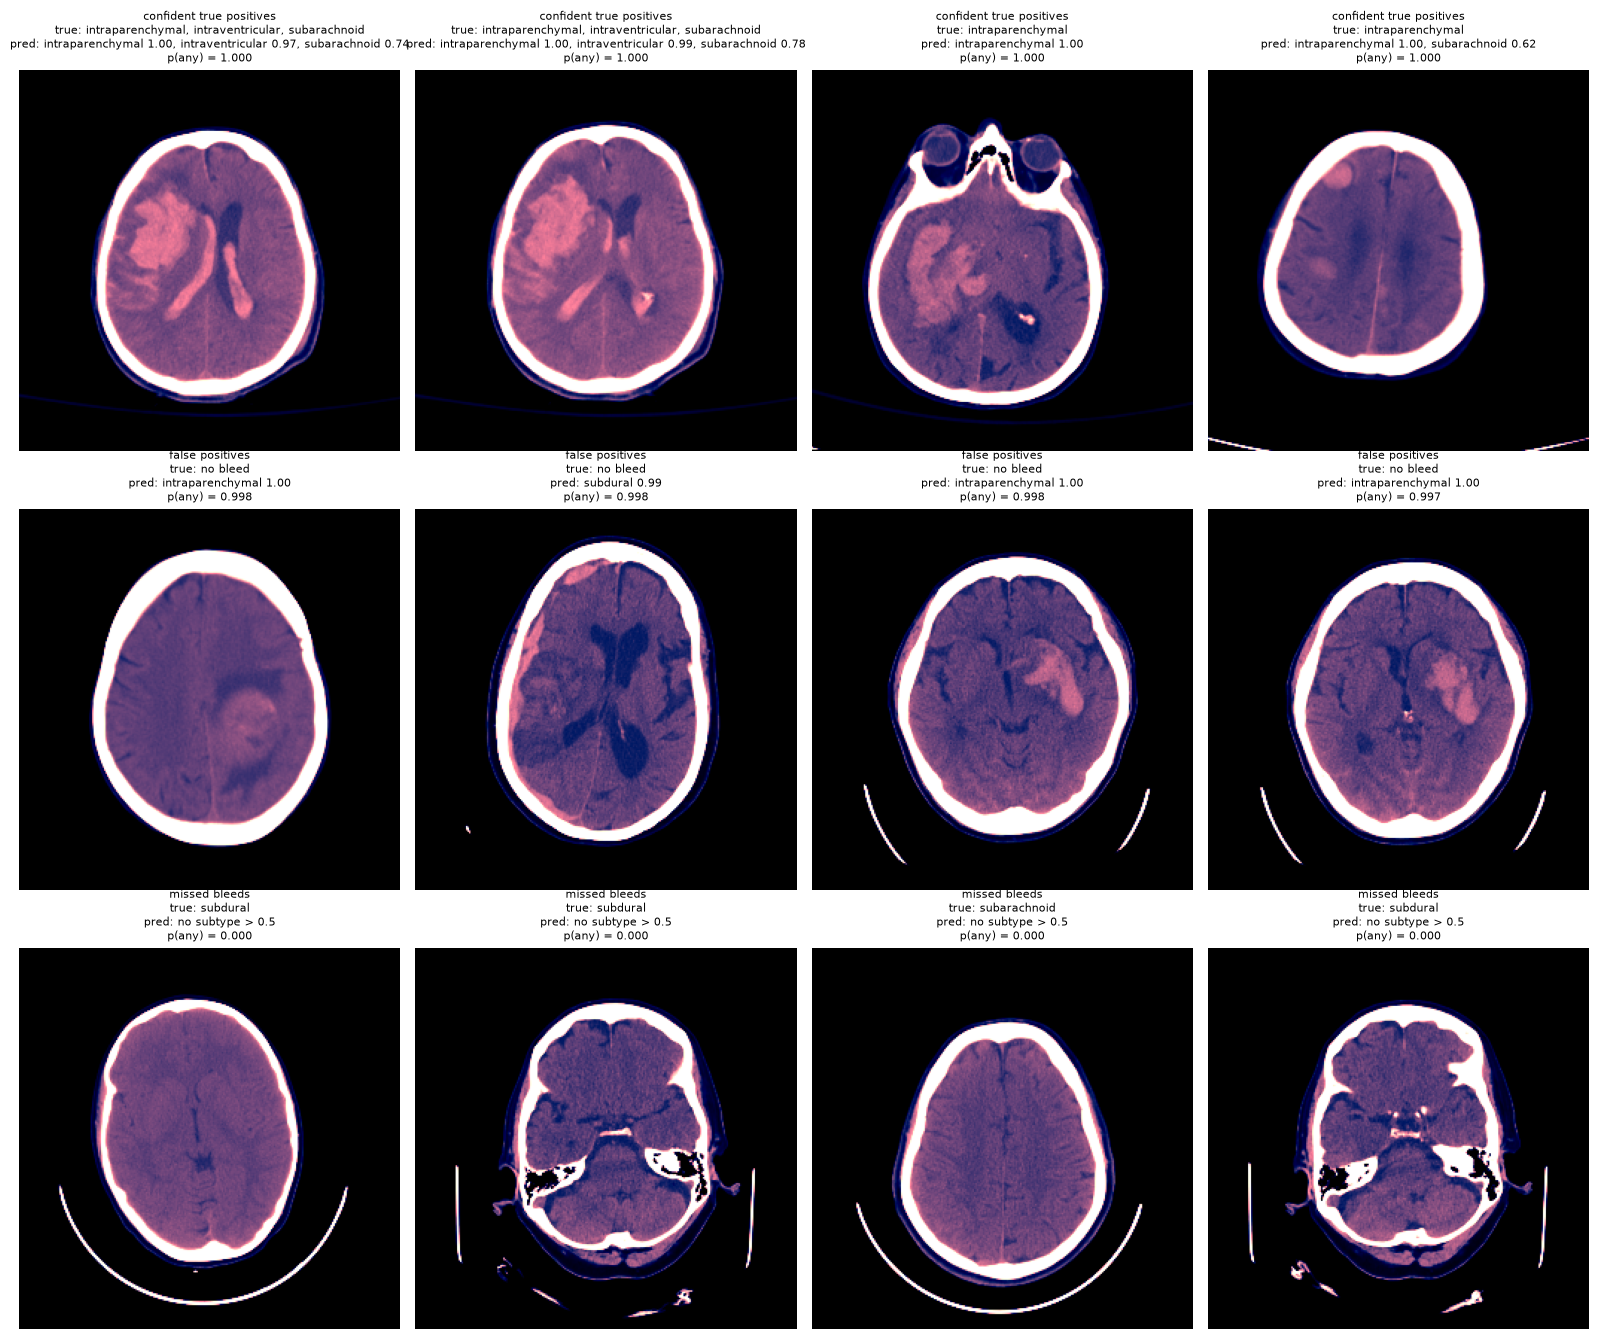

In [20]:
def pred_str(p, thr=0.5):
    hits = [(p[k], c) for k, c in enumerate(CLASSES[:-1]) if p[k] >= thr]
    return ", ".join(f"{c} {q:.2f}" for q, c in sorted(hits, reverse=True)) or "no subtype > 0.5"

ok_va = ~va["row"].isin(bad).values
pa, ya = p_val1[:, -1], y_val[:, -1]
def top(mask, by):
    i = np.where(mask)[0]
    return i[np.argsort(by[i])][:4]
rows = [("confident true positives", top(ok_va & (ya == 1), -pa)),
        ("false positives", top(ok_va & (ya == 0), -pa)),
        ("missed bleeds", top(ok_va & (ya == 1), pa))]
fig, axes = plt.subplots(3, 4, figsize=(16, 13.5), squeeze=False)
for r, (name, idx) in enumerate(rows):
    for j in range(4):
        a = axes[r, j]; a.axis("off")
        if j >= len(idx): continue
        i = idx[j]
        a.imshow(rgb_np(CACHE_ARR[int(va["row"].iloc[i])]))
        a.set_title(f"{name}\ntrue: {label_str(y_val[i])}\npred: {pred_str(p_val1[i])}\np(any) = {pa[i]:.3f}", fontsize=8)
plt.tight_layout(); save_fig("val_predictions.png"); plt.show()

### Where the model looks (Grad-CAM)

Grad-CAM weights the backbone's last feature map by the gradient of one output and upsamples it to the image: red areas raised that
output the most. It is a rough, low-resolution explanation (the feature map is 1/32 of the input size), useful for spotting a model that
looks at the wrong place (skull edge, scanner table), not a segmentation.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\gradcam.png


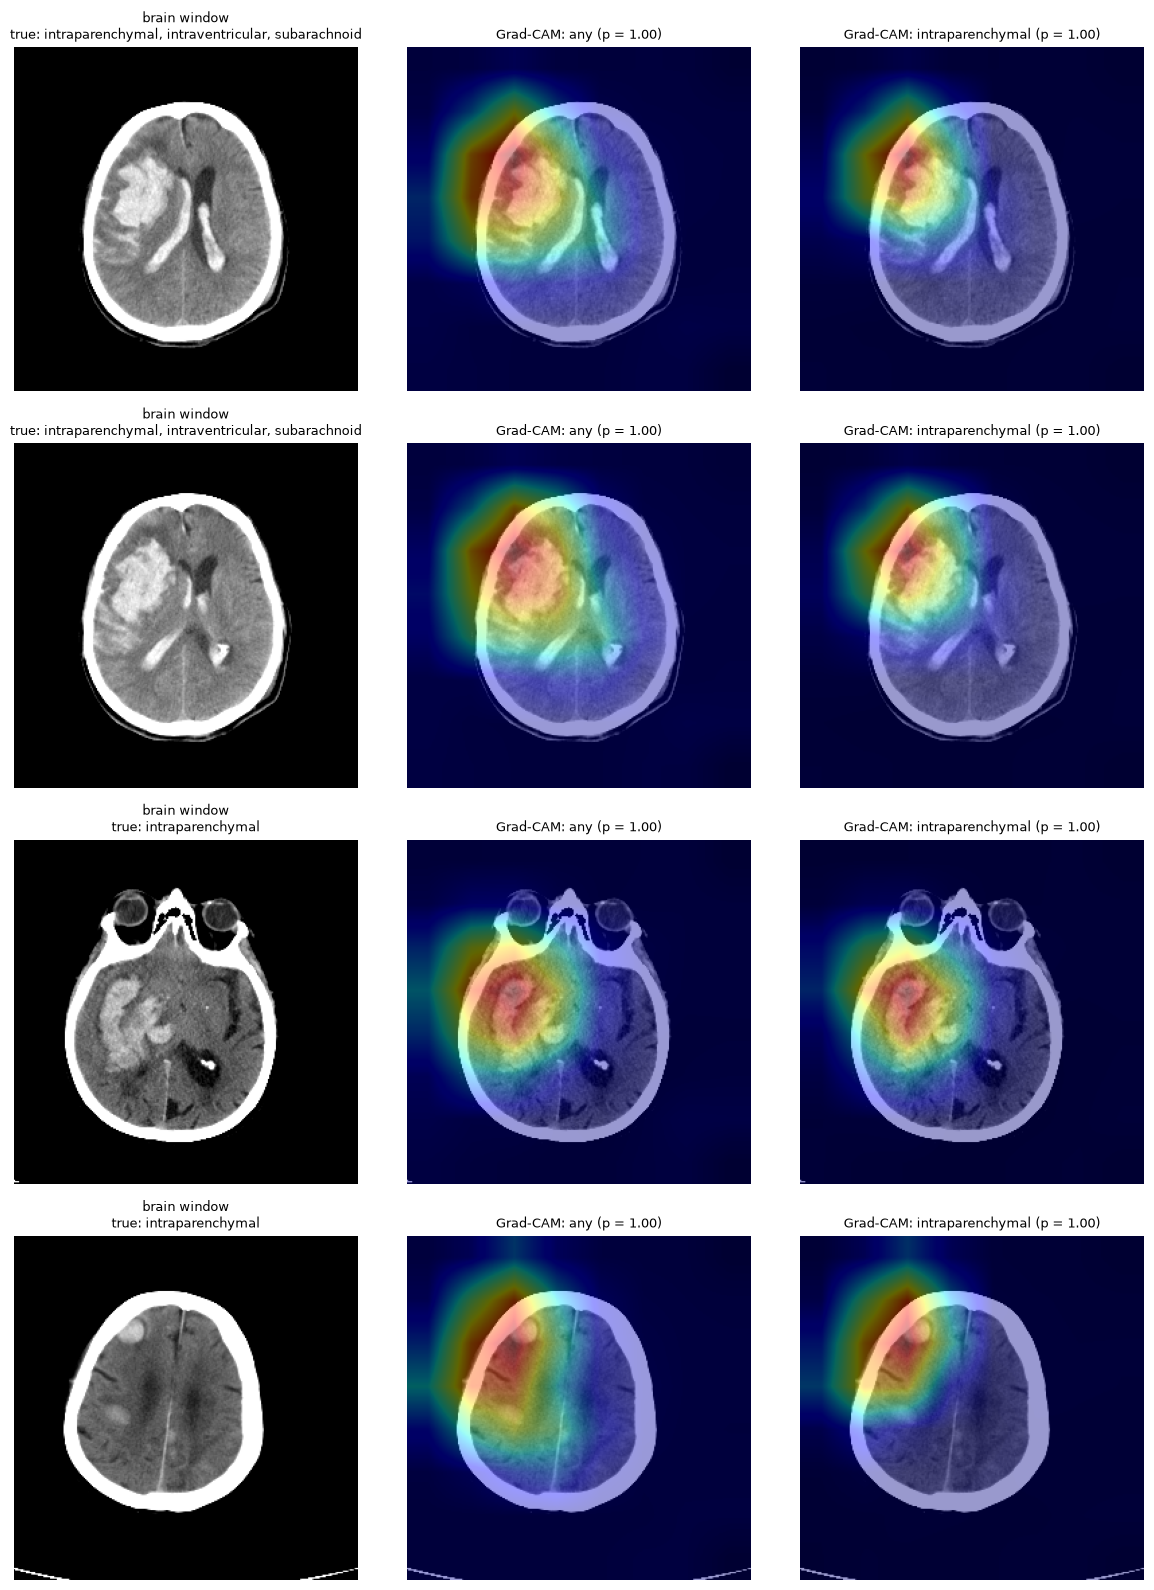

In [21]:
def grad_cam(hu, k):
    # hu: (K, S, S) HU slices -> heat map (S, S) in [0, 1] for output k, and that output's probability
    net.eval()
    with torch.enable_grad():
        fmap = net.backbone.forward_features(to_input(hu[None]))
        logit = net.head(net.backbone.forward_head(fmap, pre_logits=True))[0, k]
        g, = torch.autograd.grad(logit, fmap)
    cam = torch.relu((g.mean((2, 3), keepdim=True) * fmap).sum(1))[None]
    cam = nn.functional.interpolate(cam, size=hu.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-6)).detach().cpu().numpy(), torch.sigmoid(logit).item()

ds_va = SliceDS(va, CACHE, train=False)
cam_idx = rows[0][1]
fig, axes = plt.subplots(len(cam_idx), 3, figsize=(12, 4 * len(cam_idx)), squeeze=False)
for r, i in enumerate(cam_idx):
    hu = ds_va[int(i)][0]
    k = int(np.argmax(p_val1[i, :-1]))
    img = window_np(hu[K // 2].float().numpy(), *WINDOWS[0])
    axes[r, 0].imshow(img, cmap="gray"); axes[r, 0].set_title(f"brain window\ntrue: {label_str(y_val[i])}", fontsize=9)
    for c, (kk, nm) in enumerate([(5, "any"), (k, CLASSES[k])], start=1):
        cam, p = grad_cam(hu, kk)
        axes[r, c].imshow(img, cmap="gray"); axes[r, c].imshow(cam, cmap="jet", alpha=0.4)
        axes[r, c].set_title(f"Grad-CAM: {nm} (p = {p:.2f})", fontsize=9)
for a in axes.flat: a.axis("off")
plt.tight_layout(); save_fig("gradcam.png"); plt.show()

## 12. Sequence model over each series (stage 2)

Input per slice: the CNN's pooled features + its 6 logits. A 2-layer bidirectional GRU reads the whole series in slice order and adds a
correction to each slice's logits (the output layer starts at zero, so training starts from the CNN's own predictions).
Trained with patient-grouped K-fold on the validation series; the out-of-fold predictions give an honest score.


In [22]:
def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).astype(np.float32)

def make_seqs(frame, feats, probs, with_y=True):
    # frame rows must line up with feats/probs and be sorted by (series, z)
    frame = frame.assign(_k=np.arange(len(frame)))
    seqs = []
    for sid, g in frame.groupby("SeriesInstanceUID", sort=False):
        k = g["_k"].values
        seqs.append(dict(idx=k, pid=g["PatientID"].iloc[0], x=feats[k].astype(np.float32), l=to_logit(probs[k]),
                         y=g[CLASSES].values.astype(np.float32) if with_y else np.zeros((len(k), 6), np.float32)))
    return seqs

def collate(batch):
    L, B, F = max(len(s["idx"]) for s in batch), len(batch), batch[0]["x"].shape[1]
    x, l, y = torch.zeros(B, L, F), torch.zeros(B, L, 6), torch.zeros(B, L, 6)
    m = torch.zeros(B, L, dtype=torch.bool); lens = []
    for b, s in enumerate(batch):
        n = len(s["idx"]); lens.append(n)
        x[b, :n], l[b, :n], y[b, :n], m[b, :n] = torch.from_numpy(s["x"]), torch.from_numpy(s["l"]), torch.from_numpy(s["y"]), True
    return x, l, y, m, torch.tensor(lens)

class SeqNet(nn.Module):
    def __init__(self, n_feat, hidden=192):
        super().__init__()
        self.proj = nn.Sequential(nn.Dropout(0.3), nn.Linear(n_feat + 6, hidden), nn.ReLU())
        self.gru = nn.GRU(hidden, hidden, num_layers=2, batch_first=True, bidirectional=True, dropout=0.2)
        self.out = nn.Linear(2 * hidden, 6)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
    def forward(self, x, l, lens):
        h = self.proj(torch.cat([x, l], -1))
        packed = nn.utils.rnn.pack_padded_sequence(h, lens.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.gru(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=x.shape[1])
        return l + self.out(h)

def seq_batches(seqs, bs, shuffle):
    order = np.random.permutation(len(seqs)) if shuffle else np.arange(len(seqs))
    for i in range(0, len(order), bs):
        yield collate([seqs[j] for j in order[i:i + bs]])

def train_seq(seqs):
    m = SeqNet(N_FEAT).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-2)
    for ep in range(CFG["SEQ_EPOCHS"]):
        m.train()
        for x, l, y, mask, lens in seq_batches(seqs, 16, True):
            x, l, y, mask = x.to(DEVICE), l.to(DEVICE), y.to(DEVICE), mask.to(DEVICE)
            per = nn.functional.binary_cross_entropy_with_logits(m(x, l, lens), y, reduction="none")
            loss = ((per * W_T).sum(-1) / W_T.sum())[mask].mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return m

@torch.no_grad()
def predict_seq(models, seqs, n_rows):
    out = np.zeros((n_rows, 6), np.float32)
    for mdl in models: mdl.eval()
    for start in range(0, len(seqs), 16):
        chunk = seqs[start:start + 16]
        x, l, _, _, lens = collate(chunk)
        x, l = x.to(DEVICE), l.to(DEVICE)
        p = np.mean([torch.sigmoid(mdl(x, l, lens)).cpu().numpy() for mdl in models], axis=0)
        for b, s in enumerate(chunk):
            out[s["idx"]] = p[b, :len(s["idx"])]
    return out

USE_SEQ, seq_models = False, []
if CFG["SEQ_MODEL"]:
    seqs_val = make_seqs(va, f_val, p_val1)
    pids = np.array([s["pid"] for s in seqs_val])
    n_folds = min(CFG["SEQ_FOLDS"], len(set(pids)))
    p_val2 = np.zeros_like(p_val1)
    for fold, (a, b) in enumerate(GroupKFold(n_splits=n_folds).split(seqs_val, groups=pids)):
        m = train_seq([seqs_val[i] for i in a])
        held = [seqs_val[i] for i in b]
        pf = predict_seq([m], held, len(va))
        for s in held: p_val2[s["idx"]] = pf[s["idx"]]
        seq_models.append(m)
        print(f"fold {fold + 1}/{n_folds}: {len(a)} train series, {len(b)} held-out series")
    WLL_SEQ = weighted_logloss(y_val, p_val2)
    rep = rep.join(report(y_val, p_val2, "seq").drop(columns="val_positives"))
    USE_SEQ = WLL_SEQ < WLL_CNN
    print(f"weighted log loss on val - CNN: {WLL_CNN:.4f} | CNN + GRU (out-of-fold): {WLL_SEQ:.4f} -> using {'CNN + GRU' if USE_SEQ else 'CNN only'}")
    for i, m in enumerate(seq_models): torch.save(m.state_dict(), os.path.join(WORK, f"seq_gru_fold{i}.pt"))
display(rep.round(4))
rep.to_csv(os.path.join(WORK, "val_report.csv"))
print(elapsed())

fold 1/5: 692 train series, 173 held-out series
fold 2/5: 692 train series, 173 held-out series
fold 3/5: 692 train series, 173 held-out series
fold 4/5: 692 train series, 173 held-out series
fold 5/5: 692 train series, 173 held-out series
weighted log loss on val - CNN: 0.0970 | CNN + GRU (out-of-fold): 0.1273 -> using CNN only


,val_positives,baseline_logloss,logloss_cnn,auc_cnn,logloss_seq,auc_seq
subtype,,,,,,
epidural,123,0.0267,0.0217,0.9366,0.0317,0.8672
intraparenchymal,1503,0.1991,0.0678,0.9790,0.0818,0.9799
intraventricular,1059,0.1528,0.0418,0.9899,0.0521,0.9871
subarachnoid,1492,0.1977,0.1020,0.9460,0.1288,0.9447
subdural,2043,0.2490,0.1279,0.9455,0.1728,0.9400
any,4566,0.4270,0.1589,0.9641,0.2118,0.9655


[47 min since start]


### CNN vs. CNN + GRU along whole series

p(any) slice by slice for a few validation series that contain a bleed (red band = true label). The GRU sees the whole series,
so it can smooth isolated spikes and fill short gaps inside a run of bleeding slices. Its curve here is out-of-fold.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\series_predictions.png


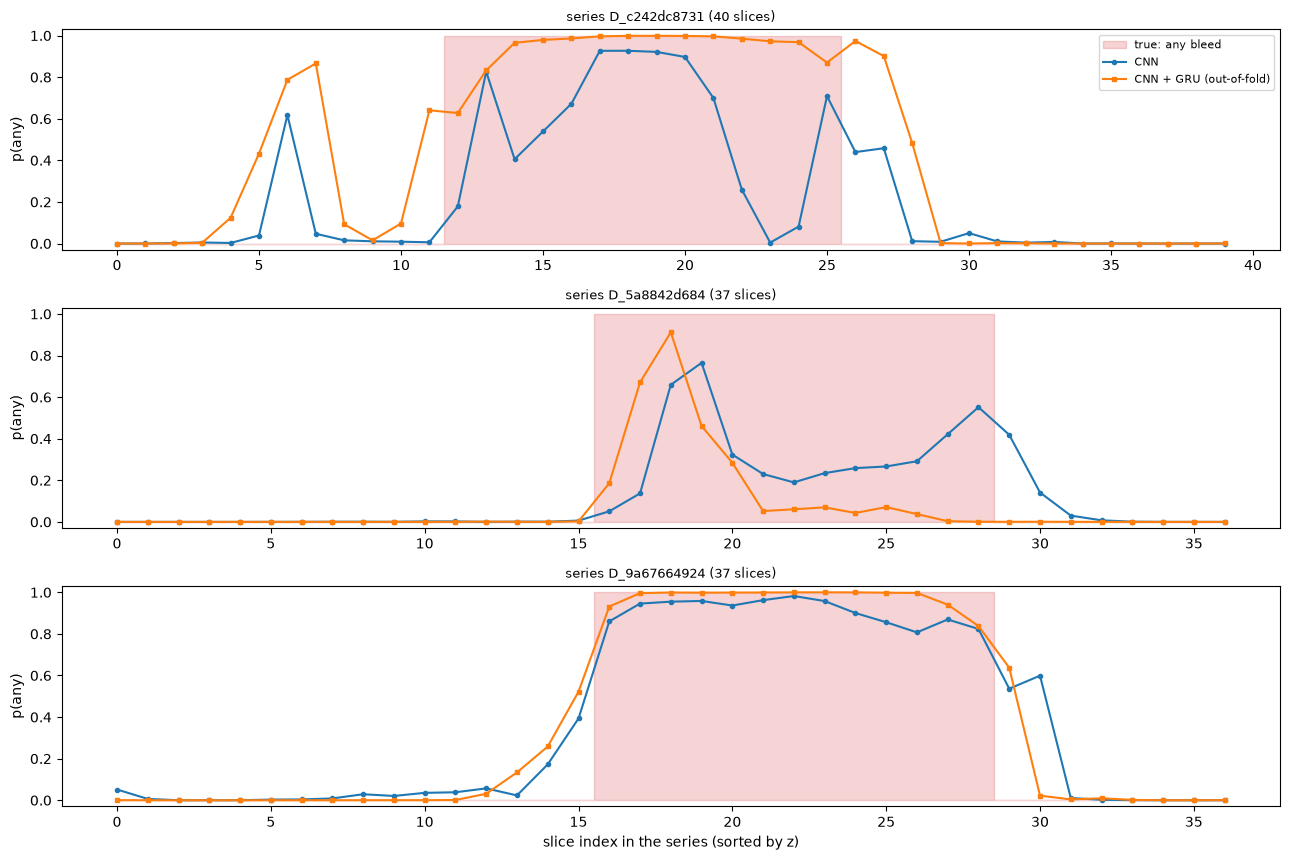

In [23]:
ser_any = va.groupby("SeriesInstanceUID")["any"].mean()
cand = ser_any[ser_any > 0]
show = (cand - 0.35).abs().sort_values(kind="stable").index[:3]
fig, axes = plt.subplots(len(show), 1, figsize=(13, 2.9 * len(show)), squeeze=False)
for a, sid in zip(axes[:, 0], show):
    k = np.where(va.SeriesInstanceUID.values == sid)[0]
    a.fill_between(range(len(k)), 0, y_val[k, -1], step="mid", color="tab:red", alpha=0.2, label="true: any bleed")
    a.plot(p_val1[k, -1], "o-", ms=3, label="CNN")
    if CFG["SEQ_MODEL"]:
        a.plot(p_val2[k, -1], "s-", ms=3, label="CNN + GRU (out-of-fold)")
    a.set_ylim(-0.03, 1.03); a.set_ylabel("p(any)"); a.set_title(f"series {sid[-12:]} ({len(k)} slices)", fontsize=9)
axes[0, 0].legend(fontsize=8, loc="upper right"); axes[-1, 0].set_xlabel("slice index in the series (sorted by z)")
plt.tight_layout(); save_fig("series_predictions.png"); plt.show()

figure saved -> d:\ML\Brain Bleed Detection on CT\assets\val_logloss_auc.png


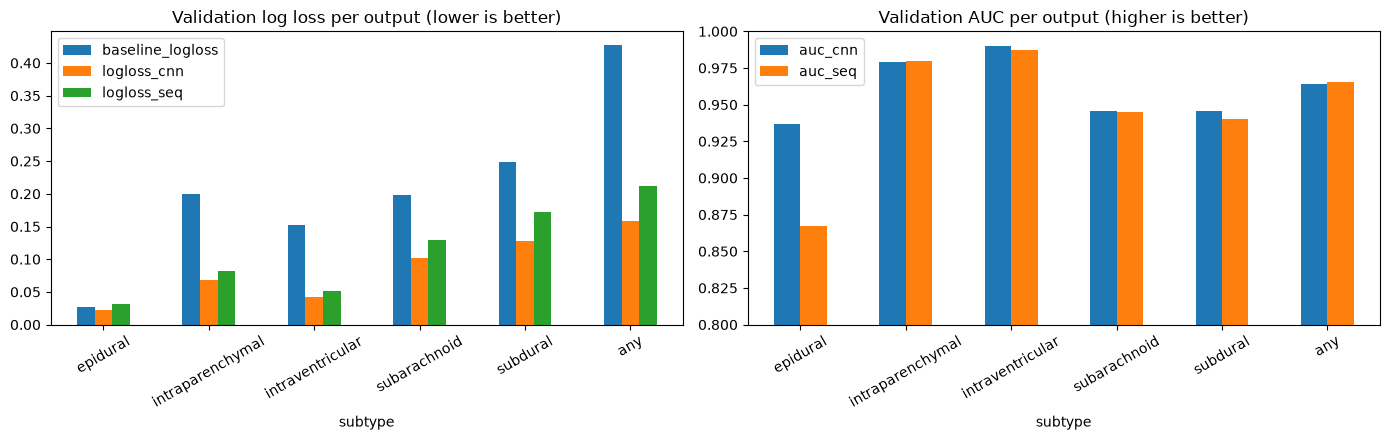

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cols = ["baseline_logloss"] + [c for c in rep.columns if c.startswith("logloss_")]
rep[cols].plot.bar(ax=ax[0]); ax[0].set_title("Validation log loss per output (lower is better)"); ax[0].tick_params(axis="x", rotation=30)
auc_cols = [c for c in rep.columns if c.startswith("auc_")]
lo = np.nanmin(rep[auc_cols].values)
rep[auc_cols].plot.bar(ax=ax[1], ylim=(min(0.8, lo - 0.02), 1.0))
ax[1].set_title("Validation AUC per output (higher is better)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(os.path.join(WORK, "results.png"), dpi=120, bbox_inches="tight")
save_fig("val_logloss_auc.png"); plt.show()

## 13. Test predictions and submission

Test headers are scanned, slices are grouped into series and sorted by z, and each series is read once (straight from DICOM)
so every slice gets its real neighbours. Output: `submission.csv` in the `ID_<image>_<subtype>, Label` format.


In [25]:
class SeriesDS(Dataset):
    def __init__(self, groups, split): self.groups, self.split = groups, split
    def __len__(self): return len(self.groups)
    def __getitem__(self, i):
        hu = [read_hu((self.split, x)) for x in self.groups[i]]
        n_bad = sum(h is None for h in hu)
        hu = np.stack([h if h is not None else np.full((S, S), HU_MIN, np.int16) for h in hu])
        return torch.from_numpy(hu), i, n_bad

def context_stack(hu):
    # (n, S, S) series in slice order -> (n, K, S, S) with (prev, cur, next), edges repeat the end slice
    if K == 1: return hu[:, None]
    ar = torch.arange(hu.shape[0])
    return hu[torch.stack([(ar - 1).clamp(min=0), ar, (ar + 1).clamp(max=hu.shape[0] - 1)], 1)]

if CFG["MAKE_SUBMISSION"]:
    ss = pd.read_csv(os.path.join(DATA, "stage_2_sample_submission.csv"))
    ss[["image", "subtype"]] = ss["ID"].str.rsplit("_", n=1, expand=True)
    test_ids = ss["image"].drop_duplicates().tolist()
    th = scan_headers(test_ids, TEST_SPLIT, os.path.join(WORK, "test_headers.csv"), CFG["TEST_HEADERS_CSV"])
    th["SeriesInstanceUID"] = th["SeriesInstanceUID"].fillna(th["image"])          # unreadable header -> its own group
    th["PatientID"] = th["PatientID"].fillna(th["image"])
    th = th.sort_values(["SeriesInstanceUID", "z", "image"], na_position="last").reset_index(drop=True)
    groups = [g["image"].tolist() for _, g in th.groupby("SeriesInstanceUID", sort=False)]
    print(f"test: {len(th)} slices in {len(groups)} series", elapsed())

    n_tot = len(th); p_test1 = np.zeros((n_tot, 6), np.float32); f_test = np.zeros((n_tot, N_FEAT), np.float16)
    order = [img for g in groups for img in g]; pos = {img: i for i, img in enumerate(order)}
    starts = np.cumsum([0] + [len(g) for g in groups])
    dl = DataLoader(SeriesDS(groups, TEST_SPLIT), batch_size=None, shuffle=False,
                    num_workers=CFG["PREP_WORKERS"] if os.name != "nt" else 0)
    n_bad, t0 = 0, time.time()
    for hu, gi, nb in tqdm(dl, total=len(groups), desc="test series"):
        n_bad += int(nb); x = context_stack(hu); P, F = [], []
        for j in range(0, len(x), CFG["BATCH"]):
            p, f = infer(x[j:j + CFG["BATCH"]]); P.append(p); F.append(f)
        p_test1[starts[gi]:starts[gi + 1]] = np.concatenate(P); f_test[starts[gi]:starts[gi + 1]] = np.concatenate(F)
    print(f"test inference {(time.time() - t0) / 60:.1f} min, unreadable slices: {n_bad}", elapsed())

    tframe = pd.DataFrame({"image": order}).merge(th[["image", "SeriesInstanceUID", "PatientID"]], on="image", how="left")
    p_final = p_test1
    if USE_SEQ:
        p_final = predict_seq(seq_models, make_seqs(tframe, f_test, p_test1, with_y=False), n_tot)

    p_final = np.clip(p_final, 1e-4, 1 - 1e-4)
    long = (pd.DataFrame(p_final, columns=CLASSES, index=pd.Index(order, name="image"))
              .reset_index().melt(id_vars="image", var_name="subtype", value_name="Label"))
    sub_df = ss[["ID", "image", "subtype"]].merge(long, on=["image", "subtype"], how="left")[["ID", "Label"]]
    assert len(sub_df) == len(ss) and sub_df["Label"].notna().all(), "submission has missing rows"
    SUB_PATH = os.path.join(WORK, "submission.csv")
    sub_df.to_csv(SUB_PATH, index=False)
    print("wrote", SUB_PATH, sub_df.shape, "| model:", "CNN + GRU" if USE_SEQ else "CNN only")
    display(sub_df.head(12))

header scan: 0 already done, 121232 to read with 16 threads


header scan:   0%|          | 0/121232 [00:00<?, ?it/s]

  headers 5000/121232 | 2252/s | ETA 1 min
  headers 10000/121232 | 2226/s | ETA 1 min
  headers 15000/121232 | 2326/s | ETA 1 min
  headers 20000/121232 | 2314/s | ETA 1 min
  headers 25000/121232 | 2355/s | ETA 1 min
  headers 30000/121232 | 2380/s | ETA 1 min
  headers 35000/121232 | 2377/s | ETA 1 min
  headers 40000/121232 | 2361/s | ETA 1 min
  headers 45000/121232 | 2334/s | ETA 1 min
  headers 50000/121232 | 2319/s | ETA 1 min
  headers 55000/121232 | 2309/s | ETA 0 min
  headers 60000/121232 | 2328/s | ETA 0 min
  headers 65000/121232 | 2358/s | ETA 0 min
  headers 70000/121232 | 2374/s | ETA 0 min
  headers 75000/121232 | 2395/s | ETA 0 min
  headers 80000/121232 | 2402/s | ETA 0 min
  headers 85000/121232 | 2419/s | ETA 0 min
  headers 90000/121232 | 2426/s | ETA 0 min
  headers 95000/121232 | 2421/s | ETA 0 min
  headers 100000/121232 | 2434/s | ETA 0 min
  headers 105000/121232 | 2417/s | ETA 0 min
  headers 110000/121232 | 2402/s | ETA 0 min
  headers 115000/121232 | 2395

test series:   0%|          | 0/3518 [00:00<?, ?it/s]

test inference 14.1 min, unreadable slices: 0 [62 min since start]
wrote d:\ML\Brain Bleed Detection on CT\Notebook\work\submission.csv (727392, 2) | model: CNN only


,ID,Label
0,ID_0fbf6a978_epidural,0.014498
1,ID_0fbf6a978_intraparenchymal,0.080921
2,ID_0fbf6a978_intraventricular,0.036300
3,ID_0fbf6a978_subarachnoid,0.117708
4,ID_0fbf6a978_subdural,0.076802
5,ID_0fbf6a978_any,0.327810
6,ID_d62ec3412_epidural,0.000100
7,ID_d62ec3412_intraparenchymal,0.000686
8,ID_d62ec3412_intraventricular,0.001980
9,ID_d62ec3412_subarachnoid,0.016229


### Test-set predictions

Distribution of the submitted p(any), the share of test slices predicted positive per output (next to the training prevalence),
and the four test slices with the highest p(any), each from a different series.


figure saved -> d:\ML\Brain Bleed Detection on CT\assets\test_predictions.png


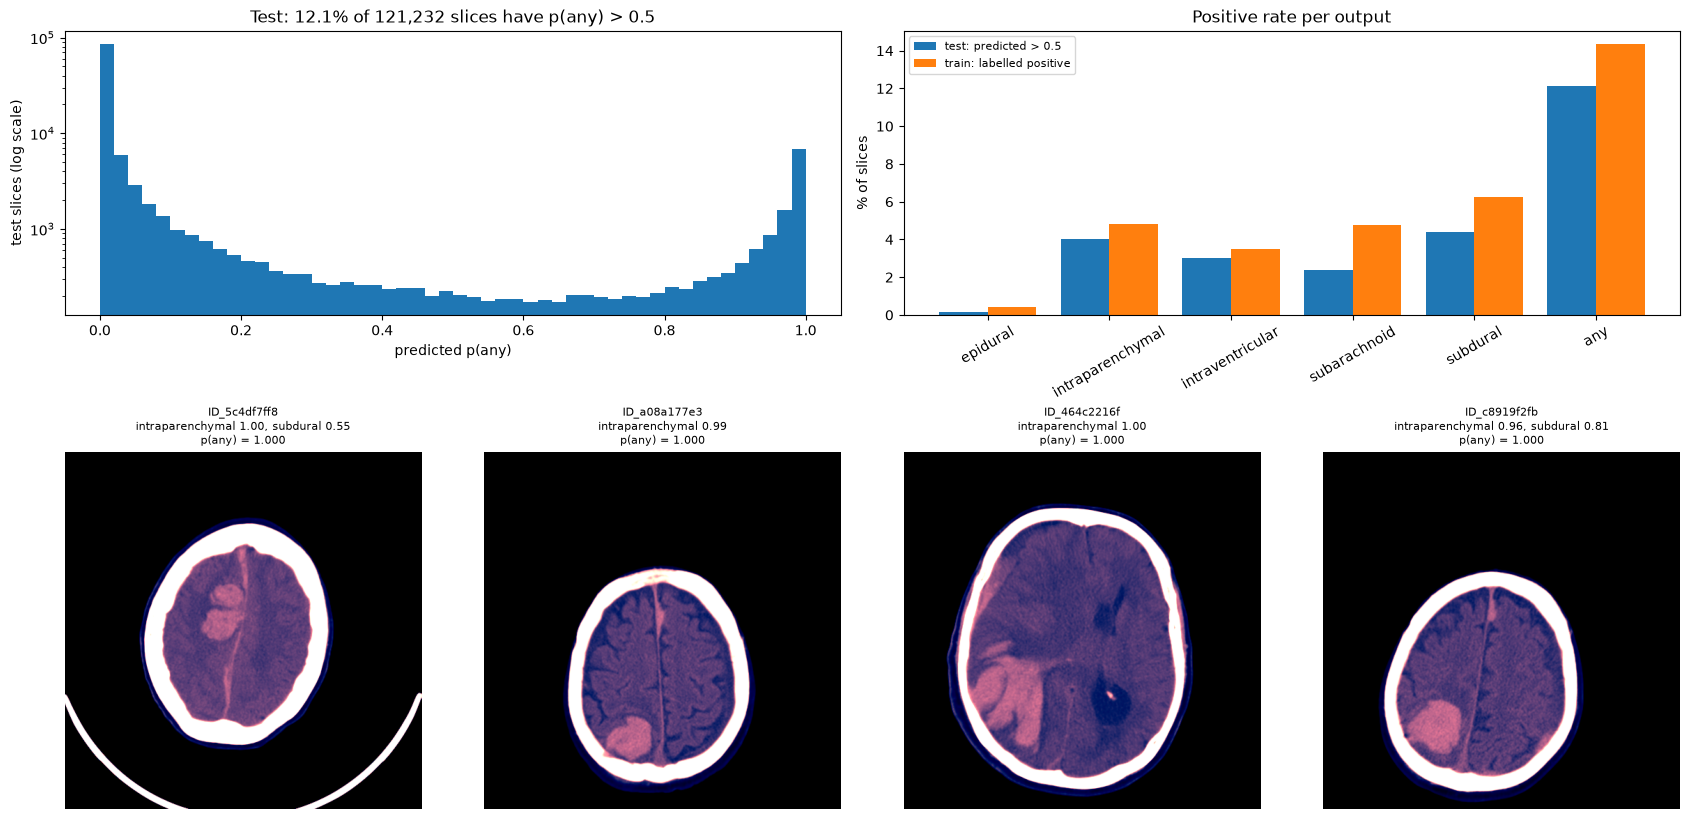

In [26]:
if CFG["MAKE_SUBMISSION"]:
    fig = plt.figure(figsize=(17, 8.5)); gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.4])
    a = fig.add_subplot(gs[0, :2])
    a.hist(p_final[:, -1], bins=50, range=(0, 1), log=True, color="#1f77b4")
    a.set_xlabel("predicted p(any)"); a.set_ylabel("test slices (log scale)")
    a.set_title(f"Test: {(p_final[:, -1] > 0.5).mean() * 100:.1f}% of {len(p_final):,} slices have p(any) > 0.5")
    b = fig.add_subplot(gs[0, 2:]); xs = np.arange(6)
    b.bar(xs - 0.2, (p_final > 0.5).mean(0) * 100, 0.4, label="test: predicted > 0.5")
    b.bar(xs + 0.2, labels[CLASSES].mean().values * 100, 0.4, label="train: labelled positive")
    b.set_xticks(xs); b.set_xticklabels(CLASSES, rotation=30); b.set_ylabel("% of slices"); b.legend(fontsize=8)
    b.set_title("Positive rate per output")
    ser_of = tframe["SeriesInstanceUID"].values; seen, top4 = set(), []
    for i in np.argsort(-p_final[:, -1]):
        if ser_of[i] not in seen:
            seen.add(ser_of[i]); top4.append(i)
        if len(top4) == 4: break
    for j, i in enumerate(top4):
        hu = full_res(TEST_SPLIT, order[i], np.full((S, S), HU_MIN, np.int16))
        ax = fig.add_subplot(gs[1, j]); ax.imshow(rgb_np(hu)); ax.axis("off")
        ax.set_title(f"{order[i]}\n{pred_str(p_final[i])}\np(any) = {p_final[i, -1]:.3f}", fontsize=8)
    plt.tight_layout(); save_fig("test_predictions.png"); plt.show()

## Notes

- Figures saved by this notebook (in `assets/` locally, `/kaggle/working/assets/` on Kaggle): `label_distribution.png`, `series_stats.png`,
  `output.png`, `hu_windows.png`, `series_labels.png`, `context_input.png`, `augmentation.png`, `roc_training_curves.png`, `calibration.png`,
  `val_predictions.png`, `gradcam.png`, `series_predictions.png`, `val_logloss_auc.png`, `test_predictions.png`.
- The figures show CT slices from the RSNA data, which may be used for non-commercial research and education only and may not be redistributed.
  Check that before publishing them.
- The real check is the Kaggle score of `submission.csv` (Save Version → Save & Run All, then Output → Submit).
- To re-run faster, add this notebook's output as a dataset: `train_headers.csv` / `test_headers.csv` are found and reused automatically.
